# Objetivo específico 2 — Diseño, ejecución y evaluación de los modelos

**Proyecto de grado:** Modelo analítico para la detección de comportamientos atípicos de funcionarios en la aprobación de créditos del sector financiero privado colombiano (Especialización en Analítica de Datos, CUN).  
**Autores:** Ángel Antonio Rodríguez Goyo, Julio Cesar Sánchez Jiménez y Gladys Dalexa Picón Solano. **Tutor:** Andrés Felipe Solís Pino.  
**Versión del código:** v0.3 (borrador del objetivo 2) · **Semilla:** 42 · **Fase CRISP-DM:** modelado y evaluación (fases 4 y 5).

> **Estado: borrador de trabajo.** Las decisiones de diseño marcadas como *supuesto* en la bitácora (sección 18) están pendientes de confirmación del tutor y del profesor. Ninguna cifra de este cuaderno se ha copiado al informe. **Métrica principal:** el protocolo del informe define el F1 de la clase anómala; el F1 macro se usa además como objetivo de Optuna y porque lo pide la lista técnica del ACA 2. Se reportan ambos.

Este cuaderno continúa el cuaderno 01. Lee `data/processed/matriz_solicitud.csv` y las etiquetas (en archivo aparte) y produce las tablas de `results/tables/`.

| Sección | Qué produce |
|---|---|
| 0 | Entorno, semilla y rutas |
| 1 | Datos, columnas excluidas y partición 70/30 **antes** de transformar |
| 2 | Tabla de ingeniería de características y comprobaciones contra fuga de información |
| 3 | Optimización de hiperparámetros con Optuna (mismo número de pruebas para todos los modelos) |
| 4 | Validación repetida 5×2 → `metricas_por_particion.csv` |
| 5 | Evaluación final en el conjunto de prueba (una sola vez) |
| 5.1 | DBSCAN: el `eps` de Optuna frente a la heurística de k-distancias |
| 6 | Comparación de los modelos y mejor modelo |
| 7 | Prueba de Wilcoxon entre particiones (complementaria) |
| 8 | Ablación en tres niveles de variables; pesos de clase frente a SMOTE |
| 9 | Sensibilidad a la contaminación |
| 10 | Nivel de funcionario |
| 10.1 | Nivel de funcionario fuera de muestra (out-of-fold) |
| 11 | Desempeño por clase y por tipo de anomalía |
| 12 | Subgrupos: tipo de producto y región |
| 13 | Estabilidad temporal 2020-2026 |
| 14 | Réplicas del generador y contraste de hipótesis H1 y H2 (Wilcoxon) |
| 15 | Figuras |
| 16–18 | Registro de experimentos, comprobaciones finales y bitácora |

**Diseño.** El núcleo del proyecto es la detección **no supervisada** (modelo base de valor Z, Isolation Forest, DBSCAN y autoencoder). Los modelos **supervisados** (regresión logística, KNN, SVM, árbol, bosque, XGBoost, LightGBM, CatBoost y red neuronal) se agregan como **referencia o «techo»**: muestran cuánto se ganaría si se contara con la etiqueta, que en un caso real no existiría.

**Uso de las etiquetas.** Nunca son variable de entrada. Se usan para evaluar y, como decisión **confirmada con el profesor**, para ajustar hiperparámetros únicamente sobre los pliegues de validación del conjunto de entrenamiento. El conjunto de prueba (30 %) permanece intacto y se usa una sola vez, al final. **Salvedad metodológica:** al guiar la búsqueda de hiperparámetros con la etiqueta, el flujo deja de ser puramente no supervisado y pasa a ser un esquema de selección de modelos supervisada (débilmente supervisado); por eso las cifras de los modelos no supervisados con parámetros ajustados no son comparables con las de parámetros fijados de antemano sin esta aclaración.

## 0. Entorno, semilla y rutas

In [1]:
import os, sys, json, hashlib, random, platform, subprocess, warnings, pathlib, time
import datetime as dt, tempfile

# ------------------------------------------------------------------
# CONFIGURACIÓN (no requiere cambios para reproducir el trabajo)
# ------------------------------------------------------------------
REPO_URL = "https://github.com/angelgoyo/analitica_datos.git"   # repositorio del proyecto (se clona solo en Colab)
SEED = 42                      # semilla fija de todo el cuaderno
N_TRIALS = 20                  # pruebas de Optuna por modelo (igual para todos)
VERSION = "v0.3"
# ------------------------------------------------------------------

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not pathlib.Path("src/modelado.py").exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "proyecto"], check=True)
    os.chdir("proyecto")
elif not pathlib.Path("src/modelado.py").exists() and pathlib.Path("../src/modelado.py").exists():
    os.chdir("..")

try:
    import optuna, xgboost, lightgbm, catboost, imblearn
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "xgboost", "lightgbm", "catboost", "imbalanced-learn"], check=True)
    import optuna, xgboost, lightgbm, catboost, imblearn

ROOT = pathlib.Path.cwd()
PROC = ROOT / "data" / "processed"; FIG = ROOT / "docs" / "figuras"; TAB = ROOT / "docs" / "tablas"
RES = ROOT / "results"; RT = RES / "tables"
for p in (FIG, TAB, RES, RT):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
from src import modelado as M
warnings.filterwarnings("ignore")
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_columns", 50, "display.width", 180)

RESULTADOS = {"version_codigo": VERSION, "semilla": SEED, "n_trials": N_TRIALS, "interpretaciones": {}}
RESULTADOS["entorno"] = {m.__name__: m.__version__ for m in (np, pd, scipy, sklearn, matplotlib, optuna, xgboost, lightgbm, catboost, imblearn)}
RESULTADOS["entorno"]["python"] = platform.python_version()

def n(x, d=0):
    s = f"{x:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")
def pct(x, d=1):
    return n(100 * x, d) + " %"
def ms(media, sd, d=3):
    return f"{n(media, d)} ± {n(sd, d)}"

AZUL, NARANJA, AGUA, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#8f8f8a", "#222222"
plt.rcParams.update({
    "font.size": 7.5, "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.labelsize": 7.5, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8f8f8a",
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.facecolor": "white", "legend.frameon": False, "text.color": TINTA, "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
})

def guardar_fig(fig, nombre):
    ruta = FIG / f"{nombre}.png"
    fig.savefig(ruta); plt.show()
    return ruta
def guardar_res(df, nombre, indice=False):
    df.to_csv(RT / f"{nombre}.csv", index=indice, encoding="utf-8-sig")
    return RT / f"{nombre}.csv"
def guardar_doc(df, nombre, indice=False):
    df.to_csv(TAB / f"{nombre}.csv", index=indice, encoding="utf-8-sig")
def interpretar(clave, titulo, frases):
    """Título y 2-3 frases de interpretación generadas con los resultados (nada se escribe a mano)."""
    texto = " ".join(frases)
    RESULTADOS["interpretaciones"][clave] = {"titulo": titulo, "texto": texto}
    display(Markdown(f"**{titulo}.** {texto}"))
def sha256(p):
    return hashlib.sha256(pathlib.Path(p).read_bytes()).hexdigest()

# ---- registro de experimentos: una fila por corrida (results/experiments.csv) ----
EXPS = []
def registrar(etapa, nivel, modelo, variante, params, met, notas="", agregacion=""):
    EXPS.append({"run_id": f"R{len(EXPS)+1:04d}", "fecha_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
                 "version_codigo": VERSION, "etapa": etapa, "nivel": nivel, "modelo": modelo, "variante": variante,
                 "semilla": SEED, "hiperparametros": json.dumps(params, ensure_ascii=False, default=float), "agregacion_metricas": agregacion, **met, "notas": notas})

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| optuna", optuna.__version__)
print("Directorio del proyecto:", ROOT)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.13.18 | scikit-learn 1.9.1 | optuna 5.0.0
Directorio del proyecto: /home/claude/work/repo


## 1. Datos, columnas excluidas y partición 70/30

La partición de prueba se hace **antes de cualquier transformación**: estratificada por la etiqueta, con semilla 42 y a nivel de solicitud (70 % entrenamiento, 30 % prueba). Todo lo que aprende parámetros (imputación, escalado, codificación, estadísticos de pares y selección de variables) está dentro de un `Pipeline` y se ajusta solo con el entrenamiento.

Las variables de calendario, los rezagos y las ventanas móviles **no aprenden parámetros** y son causales: la ventana de una solicitud solo mira solicitudes **anteriores** del mismo funcionario. Por eso se calculan antes de la partición.

In [2]:
matriz, etiq = M.cargar_datos(ROOT)
y = etiq["es_anomalia"].astype(int).values
datos = M.agregar_temporales(matriz)                       # calendario, rezagos y ventanas móviles (causales, sin etiqueta)
idx_tr, idx_te = M.particion_prueba(len(datos), y)         # 70/30 estratificada, semilla 42

COLS = M.columnas_entrada(fe=True)
X_all = datos[COLS]
X_tr, y_tr = X_all.iloc[idx_tr].reset_index(drop=True), y[idx_tr]
X_te, y_te = X_all.iloc[idx_te].reset_index(drop=True), y[idx_te]

# La partición queda fija: se registra la huella de los índices de prueba
HUELLA_PRUEBA = hashlib.sha256(idx_te.tobytes()).hexdigest()
RESULTADOS["huella_indices_prueba"] = HUELLA_PRUEBA

part = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba", "Total"],
    "Solicitudes": [len(idx_tr), len(idx_te), len(y)],
    "Anómalas": [int(y_tr.sum()), int(y_te.sum()), int(y.sum())],
})
part["% anómalas"] = (part["Anómalas"] / part["Solicitudes"] * 100).round(2)
guardar_res(part, "particion_entrenamiento_prueba")
display(part.style.hide(axis="index"))
interpretar("tab_particion", "Partición del conjunto de datos",
            [f"El conjunto se divide en {n(len(idx_tr))} solicitudes de entrenamiento y {n(len(idx_te))} de prueba; la proporción de anómalas es {pct(y_tr.mean(), 2)} y {pct(y_te.mean(), 2)}, es decir, la estratificación mantiene el desbalance.",
             "La prueba no se toca hasta la sección 5."])

# ---- columnas excluidas y por qué ----
excl = pd.DataFrame([(k, v) for k, v in M.EXCLUIDAS.items()], columns=["Columna", "Motivo de la exclusión"])
guardar_res(excl, "columnas_excluidas")
display(excl.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Conjunto,Solicitudes,Anómalas,% anómalas
Entrenamiento,6650,530,7.970000
Prueba,2850,227,7.960000
Total,9500,757,7.970000


**Partición del conjunto de datos.** El conjunto se divide en 6.650 solicitudes de entrenamiento y 2.850 de prueba; la proporción de anómalas es 7,97 % y 7,96 %, es decir, la estratificación mantiene el desbalance. La prueba no se toca hasta la sección 5.

Columna,Motivo de la exclusión
id_solicitante,Identificador: no describe comportamiento y permitiría memorizar filas.
id_funcionario_evaluador,"Identificador del funcionario: solo se usa para calcular agregados dentro del Pipeline, nunca como variable."
creditos_aprobados_funcionario,Conteo que depende de la carga de cada funcionario y coincide con las aprobaciones del dataset (fuga indirecta); se reemplaza por la tasa de aprobación.
fecha_solicitud,Se descompone en variables de calendario; la fecha cruda no se usa.
flag_gasto_mayor_ingreso,"Marca de calidad del ETL, redundante con capacidad_residual."
flag_numerico_fuera_rango,"Marca de calidad del ETL, sin variación útil."
flag_categoria_fuera_catalogo,"Marca de calidad del ETL, sin variación útil."
flag_antiguedad_incoherente,"Marca de calidad del ETL, sin variación útil."
flag_fecha_posterior_generacion,"Marca de calidad del ETL, sin variación útil."
flag_alguna,"Marca de calidad del ETL, derivada de las anteriores."


## 2. Ingeniería de características y comprobaciones contra fuga de información

La tabla resume cada variable construida con su fórmula y su justificación. Incluye **rezagos y ventanas móviles** por funcionario, **variables de calendario**, **codificación**, **escalado** y **selección** por información mutua.

In [3]:
fe = pd.DataFrame(M.FE_TABLA, columns=["Variable o paso", "Fórmula o definición", "Justificación", "Tipo", "¿Aprende parámetros?"])
guardar_doc(fe, "tabla_ingenieria_caracteristicas")
guardar_res(fe, "ingenieria_caracteristicas")
display(fe.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

# Matriz transformada con el entrenamiento (solo para describirla)
prep = M.construir_preprocesador(fe=True, categoricas=True).fit(X_tr)
nombres = prep.get_feature_names_out()
Xt = prep.transform(X_tr)
RESULTADOS["n_variables_tras_preprocesar"] = int(Xt.shape[1])
from sklearn.feature_selection import SelectPercentile, mutual_info_classif
from functools import partial
sel_ = SelectPercentile(partial(mutual_info_classif, random_state=SEED), percentile=70).fit(Xt, y_tr)   # misma selección del Pipeline supervisado
RESULTADOS["n_variables_seleccionadas"] = int(sel_.get_support().sum())
guardar_res(pd.DataFrame({"Variable": nombres, "Retenida": sel_.get_support()}), "variables_retenidas")
interpretar("tab_fe", "Variables construidas",
            [f"Tras imputar, transformar, codificar y escalar quedan {Xt.shape[1]} variables; la selección por información mutua conserva el 70 % ({RESULTADOS['n_variables_seleccionadas']}) en los modelos supervisados.",
             "Los modelos no supervisados usan solo las variables continuas, porque la selección necesitaría la etiqueta."])

Variable o paso,Fórmula o definición,Justificación,Tipo,¿Aprende parámetros?
razon_monto_ingreso,monto_solicitado / ingreso_mensual,Montos desproporcionados frente al ingreso son la señal más directa de aprobación atípica.,Razón financiera,No
razon_gasto_ingreso,gastos_mensuales / ingreso_mensual,Holgura financiera del solicitante.,Razón financiera,No
capacidad_residual,ingreso_mensual − gastos_mensuales,Capacidad de pago; negativa indica gastos mayores que el ingreso.,Razón financiera,No
cuota_estimada,monto_solicitado / plazo_solicitado_meses,Pago mensual aproximado exigido (sin intereses).,Razón financiera,No
razon_cuota_ingreso,cuota_estimada / ingreso_mensual,Carga de la cuota sobre el ingreso.,Razón financiera,No
razon_cuota_capacidad,cuota_estimada / capacidad_residual (si es positiva),Carga de la cuota sobre la capacidad real de pago.,Razón financiera,No
"mes_sin, mes_cos","sen(2π·mes/12), cos(2π·mes/12)",Codifican el mes de forma cíclica (diciembre queda cerca de enero) para capturar estacionalidad.,Calendario,No
"dia_semana, trimestre, fin_de_mes, anio","día de la semana (0-6), trimestre (1-4), 1 si el día del mes ≥ 25, año",Patrones de calendario: cierres de mes y de trimestre suelen concentrar excepciones.,Calendario,No
lag1_monto_func,monto de la solicitud anterior del mismo funcionario,Rezago de orden 1: compara con lo que el funcionario acababa de aprobar.,Rezago,No (causal)
roll5_monto_func,media del monto de las 5 solicitudes previas del funcionario,Ventana móvil: nivel reciente de montos del funcionario.,Ventana móvil,No (causal)


**Variables construidas.** Tras imputar, transformar, codificar y escalar quedan 88 variables; la selección por información mutua conserva el 70 % (61) en los modelos supervisados. Los modelos no supervisados usan solo las variables continuas, porque la selección necesitaría la etiqueta.

### 2.1 Variables más informativas (descriptivo, solo con entrenamiento)

In [4]:
from sklearn.feature_selection import mutual_info_classif
mi = mutual_info_classif(Xt, y_tr, random_state=SEED)
tabla_mi = pd.DataFrame({"Variable": nombres, "Información mutua": mi}).sort_values("Información mutua", ascending=False).reset_index(drop=True)
guardar_res(tabla_mi, "informacion_mutua_entrenamiento")
top = tabla_mi.head(12).copy(); top["Información mutua"] = top["Información mutua"].round(4)
display(top.style.hide(axis="index"))
interpretar("tab_mi", "Variables con mayor información mutua con la etiqueta (entrenamiento)",
            [f"Las tres variables con más información mutua son {top.iloc[0,0]}, {top.iloc[1,0]} y {top.iloc[2,0]}.",
             f"{int((tabla_mi['Variable'].isin(M.PEER_OUT)).head(12).sum())} de las 12 primeras son desviaciones frente a pares, calculadas solo con el entrenamiento."])

Variable,Información mutua
z_pares_monto,0.080400
z_pares_tasa_aprobacion,0.080300
z_pares_tasa_excepciones,0.078500
z_pares_razon_monto,0.077000
z_pares_tiempo,0.075500
tiempo_respuesta_dias,0.071100
roll10_excep_func,0.042600
razon_cuota_ingreso,0.039100
cuota_estimada,0.031100
roll10_aprob_func,0.027000


**Variables con mayor información mutua con la etiqueta (entrenamiento).** Las tres variables con más información mutua son z_pares_monto, z_pares_tasa_aprobacion y z_pares_tasa_excepciones. 6 de las 12 primeras son desviaciones frente a pares, calculadas solo con el entrenamiento.

### 2.2 Comprobaciones contra fuga de información

In [5]:
# (1) Ninguna columna de etiqueta ni excluida entra como variable
prohibidas = (set(M.EXCLUIDAS) - {M.COL_FUNC, "aprobado_bin", "excepcion_bin"}) | {"es_anomalia", "tipo_anomalia"}
assert not prohibidas & set(COLS), prohibidas & set(COLS)
assert not prohibidas & set(nombres), "Una columna excluida llegó a la matriz transformada."
assert M.COL_FUNC not in set(nombres), "El identificador del funcionario no debe ser variable."

# (2) Prueba con etiquetas barajadas: si el Pipeline no filtra información, el AUC debe rondar 0,5
from sklearn.model_selection import StratifiedKFold
rng = np.random.default_rng(SEED)
y_barajada = rng.permutation(y_tr)
auc = []
for tr, va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_tr, y_barajada):
    m_, *_ = M.ajustar_y_evaluar("logistica_l2", {"C": 1.0}, X_tr.iloc[tr], y_barajada[tr], X_tr.iloc[va], y_barajada[va])
    auc.append(m_["auc_roc"])
RESULTADOS["auc_etiquetas_barajadas"] = float(np.mean(auc))
assert 0.45 <= np.mean(auc) <= 0.55, "AUC con etiquetas barajadas fuera de 0,5: posible fuga."

# (3) Los estadísticos de pares salen solo del entrenamiento: un funcionario nuevo queda sin referencia
dp = M.DesviacionPares().fit(X_tr[M.PEER_IN])
RESULTADOS["funcionarios_en_referencia_pares"] = int(len(dp.ind_))
display(Markdown(f"Comprobaciones superadas: sin columnas de etiqueta como entrada; AUC con etiquetas barajadas = **{n(np.mean(auc), 3)}** (≈ 0,5, como se espera si no hay fuga); la referencia de pares se calcula con {len(dp.ind_)} funcionarios, usando solo solicitudes de entrenamiento."))

Comprobaciones superadas: sin columnas de etiqueta como entrada; AUC con etiquetas barajadas = **0,520** (≈ 0,5, como se espera si no hay fuga); la referencia de pares se calcula con 220 funcionarios, usando solo solicitudes de entrenamiento.

## 3. Optimización de hiperparámetros con Optuna

Mismo diseño para todos los modelos: muestreador TPE con semilla 42, **20 pruebas por modelo**, y como objetivo el F1 macro promedio de **3 pliegues de validación internos del entrenamiento**. La etiqueta se usa aquí solo para puntuar el pliegue de validación (esquema de selección de modelos supervisada, véase la salvedad de la introducción); el conjunto de prueba no interviene.

In [6]:
esp = M.tabla_espacios()
guardar_res(esp, "optuna_espacio_busqueda")
display(esp.style.hide(axis="index"))

Modelo,Hiperparámetro,Tipo,Rango de búsqueda
Modelo base: valor Z ≥ 3,(sin hiperparámetros),—,—
Isolation Forest,n_estimators,entero,100 a 300
Isolation Forest,max_samples,real,0.2 a 1
Isolation Forest,max_features,real,0.5 a 1
DBSCAN,eps,real (escala log),3 a 10
DBSCAN,min_samples,entero,5 a 50
Autoencoder,cuello,entero,4 a 12
Autoencoder,alpha,real (escala log),1e-05 a 0.1
Base ingenuo (clase mayoritaria),(sin hiperparámetros),—,—
Regresión logística (Ridge),C,real (escala log),0.001 a 100


In [7]:
mejores, pruebas_todas, mejor_valor, duraciones = {}, [], {}, {}
for nom in M.ORDEN:
    p, v, pr, dur = M.optimizar(nom, X_tr, y_tr, n_trials=N_TRIALS, fe=True, semilla=SEED, log=print)
    mejores[nom], mejor_valor[nom], duraciones[nom] = p, v, dur
    if len(pr):
        pruebas_todas.append(pr)
    registrar("optuna", "solicitud", nom, "con FE", p, {"f1_macro_media": v, "tiempo_s": dur}, f"{N_TRIALS} pruebas, 3 pliegues internos", agregacion="mejor prueba (media de 3 pliegues internos)")

mv = pd.DataFrame([{"Modelo": M.MODELOS[k]["etiqueta"], "clave": k, "Pruebas": (N_TRIALS if M.MODELOS[k]["espacio"] else 0),
                    "Mejor F1 macro interno": mejor_valor[k], "Mejores valores": json.dumps(mejores[k], ensure_ascii=False, default=lambda o: round(float(o), 6)),
                    "Duración (s)": round(duraciones[k], 1)} for k in M.ORDEN])
guardar_res(mv, "optuna_mejores_valores")
guardar_res(pd.concat(pruebas_todas, ignore_index=True), "optuna_pruebas")
vis = mv.drop(columns="clave").copy(); vis["Mejor F1 macro interno"] = vis["Mejor F1 macro interno"].round(4)
display(vis.style.hide(axis="index").set_properties(**{"text-align": "left"}))
tuneados = mv[mv["Pruebas"] > 0]
mejor_fila = tuneados.sort_values("Mejor F1 macro interno", ascending=False).iloc[0]
interpretar("tab_optuna", "Mejores hiperparámetros por modelo",
            [f"Cada uno de los {len(tuneados)} modelos con hiperparámetros recibió {N_TRIALS} pruebas; el mayor F1 macro en validación interna lo obtuvo {mejor_fila['Modelo']} ({n(mejor_fila['Mejor F1 macro interno'], 3)}).",
             "El modelo base de valor Z y el base ingenuo no tienen hiperparámetros que ajustar. Los valores completos y las 20 pruebas de cada modelo están en `results/tables/optuna_pruebas.csv`."])

  isolation_forest: mejor F1 macro interno 0.7025 (32 s)


  dbscan: mejor F1 macro interno 0.7787 (9 s)


  autoencoder: mejor F1 macro interno 0.6915 (91 s)


  logistica_l2: mejor F1 macro interno 0.8292 (71 s)


  logistica_l1: mejor F1 macro interno 0.8286 (162 s)


  knn: mejor F1 macro interno 0.8955 (80 s)


... (5 outputs left out)

  catboost: mejor F1 macro interno 0.9683 (128 s)


  mlp: mejor F1 macro interno 0.9349 (83 s)


Modelo,Pruebas,Mejor F1 macro interno,Mejores valores,Duración (s)
Modelo base: valor Z ≥ 3,0,nan,{},0.000000
Isolation Forest,20,0.702500,"{""n_estimators"": 242, ""max_samples"": 0.21646759543664196, ""max_features"": 0.9849549260809971}",31.800000
DBSCAN,20,0.778700,"{""eps"": 5.698469223877077, ""min_samples"": 29}",9.200000
Autoencoder,20,0.691500,"{""cuello"": 4, ""alpha"": 0.029154431891537533}",91.200000
Base ingenuo (clase mayoritaria),0,nan,{},0.000000
Regresión logística (Ridge),20,0.829200,"{""C"": 9.154902491428649}",71.300000
Regresión logística (Lasso),20,0.828600,"{""C"": 7.61045932406855}",161.600000
K vecinos más cercanos,20,0.895500,"{""n_neighbors"": 3, ""weights"": ""distance"", ""p"": 2}",80.400000
Máquina de soporte vectorial (RBF),20,0.941900,"{""C"": 88.64947819116749, ""gamma"": 0.024920354039946066}",118.000000
Árbol de decisión,20,0.935800,"{""max_depth"": 12, ""min_samples_leaf"": 1}",72.300000


**Mejores hiperparámetros por modelo.** Cada uno de los 13 modelos con hiperparámetros recibió 20 pruebas; el mayor F1 macro en validación interna lo obtuvo CatBoost (0,968). El modelo base de valor Z y el base ingenuo no tienen hiperparámetros que ajustar. Los valores completos y las 20 pruebas de cada modelo están en `results/tables/optuna_pruebas.csv`.

## 4. Validación repetida 5×2 sobre el entrenamiento

Cada modelo, con sus mejores hiperparámetros, se evalúa en **10 particiones** (`RepeatedStratifiedKFold`, 5 pliegues × 2 repeticiones, semilla 42). En cada partición todo el `Pipeline` se ajusta solo con el entrenamiento de esa partición. El resultado, una fila por modelo y partición, es `results/tables/metricas_por_particion.csv`.

In [8]:
cv_filas = []
for nom in M.ORDEN:
    df = M.validacion_repetida(nom, mejores[nom], X_tr, y_tr, fe=True)
    cv_filas.append(df)
    registrar("validacion_5x2", "solicitud", nom, "con FE", mejores[nom],
              {"f1_macro_media": df.f1_macro.mean(), "f1_macro_sd": df.f1_macro.std(), "auc_roc_media": df.auc_roc.mean(),
               "auc_pr_media": df.auc_pr.mean(), "mcc_media": df.mcc.mean(), "tiempo_s": df.tiempo_ajuste_s.mean()}, "10 particiones", agregacion="media de 10 particiones")
    print(f"{nom:18s} F1 macro {df.f1_macro.mean():.3f} ± {df.f1_macro.std():.3f}")
cv = pd.concat(cv_filas, ignore_index=True)
assert (cv.groupby("modelo").size() == 10).all(), "Cada modelo debe tener 10 particiones."
guardar_res(cv, "metricas_por_particion")
resumen_cv = M.resumir(cv).loc[M.ORDEN]
guardar_res(resumen_cv.reset_index(), "resumen_validacion")

z_base             F1 macro 0.729 ± 0.019


isolation_forest   F1 macro 0.704 ± 0.025


dbscan             F1 macro 0.799 ± 0.020


autoencoder        F1 macro 0.690 ± 0.021


base_ingenuo       F1 macro 0.479 ± 0.000


logistica_l2       F1 macro 0.838 ± 0.013


... (6 outputs left out)

lightgbm           F1 macro 0.964 ± 0.010


catboost           F1 macro 0.963 ± 0.009


mlp                F1 macro 0.929 ± 0.011


PosixPath('/home/claude/work/repo/results/tables/resumen_validacion.csv')

## 5. Evaluación final en el conjunto de prueba

Cada modelo se ajusta **una vez** con todo el entrenamiento y sus mejores hiperparámetros, y se evalúa **una sola vez** en la prueba. Para los modelos no supervisados, la etiqueta no interviene en el ajuste.

In [9]:
prueba_filas, finales, salidas_prueba = [], {}, {}
for nom in M.ORDEN:
    m_, pred, s, pipe = M.ajustar_y_evaluar(nom, mejores[nom], X_tr, y_tr, X_te, y_te, fe=True)
    finales[nom] = pipe; salidas_prueba[nom] = (pred, s)
    m_.update({"modelo": nom})
    prueba_filas.append(m_)
    registrar("prueba", "solicitud", nom, "con FE", mejores[nom], {"f1_macro_media": m_["f1_macro"], "auc_roc_media": m_["auc_roc"], "auc_pr_media": m_["auc_pr"], "mcc_media": m_["mcc"], "precision": m_["precision"], "recall": m_["recall"], "tiempo_s": m_["tiempo_ajuste_s"]}, "evaluación única", agregacion="corrida única en la prueba")
prueba = pd.DataFrame(prueba_filas).set_index("modelo").loc[M.ORDEN]
guardar_res(prueba.reset_index(), "resultados_prueba")
cm = prueba[["tn", "fp", "fn", "tp"]].reset_index()
cm.insert(1, "Modelo", [M.MODELOS[k]["etiqueta"] for k in cm["modelo"]])
guardar_res(cm.drop(columns="modelo"), "matrices_confusion_prueba")
display(cm.drop(columns="modelo").rename(columns={"tn": "Verdaderos negativos", "fp": "Falsos positivos", "fn": "Falsos negativos", "tp": "Verdaderos positivos"}).style.hide(axis="index"))
mejor_prueba = prueba.drop(index=["base_ingenuo"]).sort_values("f1_macro", ascending=False).index[0]
interpretar("tab_confusion", "Matrices de confusión de cada modelo en el conjunto de prueba",
            [f"La prueba tiene {n(int(y_te.sum()))} solicitudes anómalas de {n(len(y_te))}; {M.MODELOS[mejor_prueba]['etiqueta']} acierta {int(prueba.loc[mejor_prueba,'tp'])} y deja pasar {int(prueba.loc[mejor_prueba,'fn'])}, con {int(prueba.loc[mejor_prueba,'fp'])} falsas alarmas.",
             "El modelo base ingenuo clasifica todo como normal y no detecta ninguna anomalía, lo que fija el piso de comparación."])

Modelo,Verdaderos negativos,Falsos positivos,Falsos negativos,Verdaderos positivos
Modelo base: valor Z ≥ 3,2320,303,37,190
Isolation Forest,2491,132,128,99
DBSCAN,2554,69,100,127
Autoencoder,2486,137,121,106
Base ingenuo (clase mayoritaria),2623,0,227,0
Regresión logística (Ridge),2468,155,15,212
Regresión logística (Lasso),2469,154,16,211
K vecinos más cercanos,2618,5,64,163
Máquina de soporte vectorial (RBF),2608,15,30,197
Árbol de decisión,2576,47,29,198


**Matrices de confusión de cada modelo en el conjunto de prueba.** La prueba tiene 227 solicitudes anómalas de 2.850; LightGBM acierta 200 y deja pasar 27, con 4 falsas alarmas. El modelo base ingenuo clasifica todo como normal y no detecta ninguna anomalía, lo que fija el piso de comparación.

## 5.1 DBSCAN: el `eps` hallado con Optuna frente a la heurística de k-distancias

El `eps` de DBSCAN se eligió con Optuna, y esa búsqueda usa la etiqueta en la validación interna del entrenamiento (la salvedad se declara en la metodología). Como contraste **sin etiquetas** se aplica la heurística clásica del **gráfico de k-distancias**: para cada solicitud de entrenamiento se calcula la distancia a su vecino número *k* y se ordenan de menor a mayor; el «codo» de la curva (el punto más alejado de la recta que une los extremos) sugiere un `eps` que separa los puntos densos de los aislados. Se prueban dos valores de *k*: el `min_samples` que halló Optuna y la regla de Sander et al. (*k* = 2 × número de variables).

Esta comparación **no se usa para elegir el modelo**: el conjunto de prueba solo describe cuánto se parecen los dos caminos. La curva se calcula en el espacio de variables ya transformado con el entrenamiento.

Camino para elegir eps,min_samples,eps,% de entrenamiento marcado como ruido,Marcadas en prueba,Precision,Recall,F1 anómala,AUC-PR,AUC-ROC
Optuna (con etiqueta en validación interna),29,5.698000,6.060000,196,0.648000,0.559000,0.600000,0.480000,0.901000
Codo con k = 29 (min_samples de Optuna),29,6.546000,1.759000,54,0.370000,0.088000,0.142000,0.376000,0.867000
Codo con k = 2·d = 74 (Sander et al.),74,6.833000,1.970000,64,0.484000,0.137000,0.213000,0.439000,0.888000


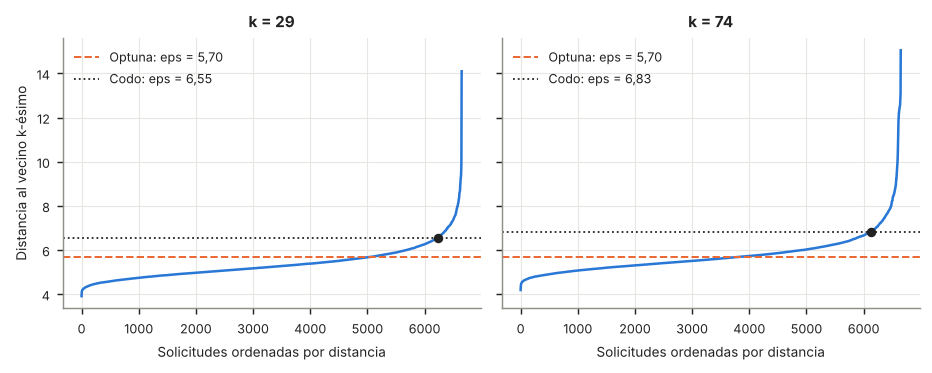

**Valor de eps de DBSCAN: Optuna frente al gráfico de k-distancias.** Optuna eligió eps = 5,70 con min_samples = 29. El codo del gráfico de k-distancias da eps = 6,55 con k = 29 y eps = 6,83 con k = 74. En la prueba, el F1 de la clase anómala es 0,60 con el eps de Optuna, 0,14 con el primer codo y 0,21 con el segundo; la diferencia con el camino supervisado es de -0,46 y -0,39. La heurística no usa etiquetas, por lo que su resultado indica cuánto del desempeño de DBSCAN depende de haber guiado la búsqueda con ellas; con una sola partición de prueba la diferencia es descriptiva.

In [10]:
from sklearn.neighbors import NearestNeighbors
pipe_db = finales["dbscan"]
Xp_tr, Xp_te = pipe_db[:-1].transform(X_tr), pipe_db[:-1].transform(X_te)
d_esp = Xp_tr.shape[1]
eps_opt, k_opt = float(mejores["dbscan"]["eps"]), int(mejores["dbscan"]["min_samples"])

def curva_k(k):
    """Distancia al vecino k-ésimo (el punto cuenta como uno de los `min_samples` que pide DBSCAN), ordenada."""
    d, _ = NearestNeighbors(n_neighbors=k).fit(Xp_tr).kneighbors(Xp_tr)
    return np.sort(d[:, k - 1])
def codo(kd):
    """Punto de la curva más alejado de la recta entre sus extremos (curva normalizada a [0, 1])."""
    x = np.linspace(0, 1, len(kd)); yn = (kd - kd.min()) / (kd.max() - kd.min())
    i = int(np.argmax(x - yn)); return i, float(kd[i])

variantes = [("Optuna (con etiqueta en validación interna)", eps_opt, k_opt, None)]
curvas = {}
for et, k in ((f"Codo con k = {k_opt} (min_samples de Optuna)", k_opt), (f"Codo con k = 2·d = {2 * d_esp} (Sander et al.)", 2 * d_esp)):
    kd = curva_k(k); i, e = codo(kd); curvas[et] = (kd, i, e, k)
    variantes.append((et, e, k, i))

filas = []
for et, e, k, _ in variantes:
    det = M.DetectorDBSCAN(eps=e, min_samples=k).fit(Xp_tr)
    pred_tr, pred_te, sc_te = det.predict(Xp_tr), det.predict(Xp_te), det.score_anomalia(Xp_te)
    mt = M.metricas(y_te, pred_te.astype(int), sc_te)
    filas.append({"Camino para elegir eps": et, "min_samples": k, "eps": e, "% de entrenamiento marcado como ruido": 100 * pred_tr.mean(),
                  "Marcadas en prueba": int(pred_te.sum()), "Precision": mt["precision"], "Recall": mt["recall"], "F1 anómala": mt["f1_anomalia"],
                  "AUC-PR": mt["auc_pr"], "AUC-ROC": mt["auc_roc"]})
    registrar("kdistancia", "solicitud", "dbscan", et, {"eps": e, "min_samples": k}, {"f1_macro_media": mt["f1_macro"], "auc_pr_media": mt["auc_pr"], "precision": mt["precision"], "recall": mt["recall"]}, "contraste sin etiquetas del eps; la prueba solo describe", agregacion="corrida única en la prueba")
kdist = pd.DataFrame(filas)
guardar_res(kdist, "dbscan_eps_kdistancia")
# control: la fila de Optuna reproduce el resultado de la sección 5
assert abs(kdist.loc[0, "F1 anómala"] - prueba.loc["dbscan", "f1_anomalia"]) < 1e-9, "La fila de Optuna debe coincidir con la evaluación final."
vis = kdist.copy()
for c in ("eps", "% de entrenamiento marcado como ruido", "Precision", "Recall", "F1 anómala", "AUC-PR", "AUC-ROC"): vis[c] = vis[c].round(3)
display(vis.style.hide(axis="index").set_properties(**{"text-align": "left"}))

fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.9), sharey=True)
for ax, (et, (kd, i, e, k)) in zip(axs, curvas.items()):
    ax.plot(np.arange(len(kd)), kd, color=AZUL, lw=1.4)
    ax.axhline(eps_opt, color=NARANJA, ls="--", lw=1.1, label=f"Optuna: eps = {n(eps_opt, 2)}")
    ax.scatter([i], [e], color=TINTA, zorder=5, s=18); ax.axhline(e, color=TINTA, ls=":", lw=1.0, label=f"Codo: eps = {n(e, 2)}")
    ax.set_title(f"k = {k}"); ax.set_xlabel("Solicitudes ordenadas por distancia"); ax.legend(loc="upper left")
axs[0].set_ylabel(f"Distancia al vecino k-ésimo")
fig.tight_layout()
guardar_fig(fig, "fig_kdistancia_dbscan")
dif = kdist.loc[1:, "F1 anómala"] - kdist.loc[0, "F1 anómala"]
RESULTADOS["dbscan_kdistancia"] = {"eps_optuna": eps_opt, "k_optuna": k_opt, "n_variables": int(d_esp),
    "variantes": [{"camino": r["Camino para elegir eps"], "k": int(r["min_samples"]), "eps": float(r["eps"]), "f1": float(r["F1 anómala"]), "precision": float(r["Precision"]), "recall": float(r["Recall"])} for _, r in kdist.iterrows()]}
interpretar("tab_dbscan_kdistancia", "Valor de eps de DBSCAN: Optuna frente al gráfico de k-distancias",
            [f"Optuna eligió eps = {n(eps_opt, 2)} con min_samples = {k_opt}. El codo del gráfico de k-distancias da eps = {n(kdist.loc[1, 'eps'], 2)} con k = {k_opt} y eps = {n(kdist.loc[2, 'eps'], 2)} con k = {2 * d_esp}.",
             f"En la prueba, el F1 de la clase anómala es {n(kdist.loc[0, 'F1 anómala'], 2)} con el eps de Optuna, {n(kdist.loc[1, 'F1 anómala'], 2)} con el primer codo y {n(kdist.loc[2, 'F1 anómala'], 2)} con el segundo; la diferencia con el camino supervisado es de {n(dif.iloc[0], 2)} y {n(dif.iloc[1], 2)}.",
             "La heurística no usa etiquetas, por lo que su resultado indica cuánto del desempeño de DBSCAN depende de haber guiado la búsqueda con ellas; con una sola partición de prueba la diferencia es descriptiva."])

## 6. Comparación de los modelos

La tabla resume el F1 macro, el AUC-ROC, el AUC-PR y el MCC como **media ± desviación estándar de las 10 particiones**, junto con el tiempo de ajuste y el resultado en la prueba.

In [11]:
filas = []
for nom in M.ORDEN:
    r, p = resumen_cv.loc[nom], prueba.loc[nom]
    filas.append({"Modelo": M.MODELOS[nom]["etiqueta"], "Tipo": "No supervisado" if M.MODELOS[nom]["tipo"] == "nosup" else ("Referencia" if nom == "base_ingenuo" else "Supervisado (referencia)"),
                  "F1 anómala (validación)": ms(r.f1_anomalia_media, r.f1_anomalia_sd), "F1 macro (validación)": ms(r.f1_macro_media, r.f1_macro_sd), "AUC-ROC (validación)": ms(r.auc_roc_media, r.auc_roc_sd),
                  "AUC-PR (validación)": ms(r.auc_pr_media, r.auc_pr_sd), "MCC (validación)": ms(r.mcc_media, r.mcc_sd),
                  "Tiempo de ajuste (s)": n(r.tiempo_ajuste_s_media, 2),
                  "F1 anómala (prueba)": n(p.f1_anomalia, 3), "F1 macro (prueba)": n(p.f1_macro, 3), "AUC-ROC (prueba)": n(p.auc_roc, 3), "AUC-PR (prueba)": n(p.auc_pr, 3), "MCC (prueba)": n(p.mcc, 3)})
comp = pd.DataFrame(filas)
guardar_res(comp, "resumen_modelos")
guardar_doc(comp, "tabla_resumen_modelos")
display(comp.style.hide(axis="index").set_properties(**{"text-align": "left"}))

nosup = [k for k in M.ORDEN_NOSUP if k != "z_base"]
sup = [k for k in M.ORDEN_SUP if k != "base_ingenuo"]
mejor_nosup = max(nosup, key=lambda k: resumen_cv.loc[k, "f1_macro_media"])
mejor_sup = max(sup, key=lambda k: resumen_cv.loc[k, "f1_macro_media"])
RESULTADOS["mejor_no_supervisado"] = mejor_nosup; RESULTADOS["mejor_supervisado"] = mejor_sup
z = resumen_cv.loc["z_base", "f1_macro_media"]
interpretar("tab_comparacion", "Comparación de modelos en validación y prueba",
            [f"Entre los modelos no supervisados, {M.MODELOS[mejor_nosup]['etiqueta']} obtiene el mayor F1 macro de validación ({n(resumen_cv.loc[mejor_nosup,'f1_macro_media'], 3)}) frente a {n(z, 3)} del modelo base de valor Z; entre los supervisados, que usan la etiqueta, lidera {M.MODELOS[mejor_sup]['etiqueta']} ({n(resumen_cv.loc[mejor_sup,'f1_macro_media'], 3)}).",
             f"Sin depender del umbral, el AUC-PR de validación es {n(resumen_cv.loc[mejor_nosup,'auc_pr_media'], 2)} para {M.MODELOS[mejor_nosup]['etiqueta']} y {n(resumen_cv.loc['z_base','auc_pr_media'], 2)} para el modelo base; el F1 macro de DBSCAN depende además de `eps`, que se ajustó con la etiqueta, mientras que el umbral del modelo base (Z ≥ 3) y la contaminación de Isolation Forest y del autoencoder (7,5 %) se fijaron de antemano, por lo que la comparación favorece a los detectores con parámetro ajustado.",
             f"La diferencia entre ambos grupos ({n(resumen_cv.loc[mejor_sup,'f1_macro_media'] - resumen_cv.loc[mejor_nosup,'f1_macro_media'], 3)} puntos de F1 macro) estima lo que aportaría contar con la etiqueta.",
             f"El AUC-PR es la métrica más exigente con el desbalance: un clasificador al azar obtiene alrededor de la prevalencia ({n(y_te.mean(), 2)})."])

Modelo,Tipo,F1 anómala (validación),F1 macro (validación),AUC-ROC (validación),AUC-PR (validación),MCC (validación),Tiempo de ajuste (s),F1 anómala (prueba),F1 macro (prueba),AUC-ROC (prueba),AUC-PR (prueba),MCC (prueba)
Modelo base: valor Z ≥ 3,No supervisado,"0,526 ± 0,030","0,729 ± 0,019","0,937 ± 0,007","0,508 ± 0,028","0,513 ± 0,031","0,03","0,528","0,730","0,936","0,513","0,516"
Isolation Forest,No supervisado,"0,457 ± 0,047","0,704 ± 0,025","0,881 ± 0,019","0,462 ± 0,059","0,409 ± 0,050","0,52","0,432","0,691","0,867","0,448","0,383"
DBSCAN,No supervisado,"0,629 ± 0,036","0,799 ± 0,020","0,930 ± 0,012","0,534 ± 0,040","0,598 ± 0,039","0,09","0,600","0,784","0,901","0,480","0,570"
Autoencoder,No supervisado,"0,431 ± 0,039","0,690 ± 0,021","0,781 ± 0,031","0,336 ± 0,047","0,381 ± 0,043","1,35","0,451","0,701","0,777","0,318","0,402"
Base ingenuo (clase mayoritaria),Referencia,"0,000 ± 0,000","0,479 ± 0,000","0,500 ± 0,000","0,080 ± 0,000","0,000 ± 0,000","0,05","0,000","0,479","0,500","0,080","0,000"
Regresión logística (Ridge),Supervisado (referencia),"0,709 ± 0,022","0,838 ± 0,013","0,979 ± 0,004","0,858 ± 0,020","0,701 ± 0,020","1,49","0,714","0,840","0,985","0,908","0,707"
Regresión logística (Lasso),Supervisado (referencia),"0,707 ± 0,023","0,836 ± 0,014","0,979 ± 0,004","0,858 ± 0,020","0,699 ± 0,022","4,42","0,713","0,840","0,985","0,908","0,706"
K vecinos más cercanos,Supervisado (referencia),"0,817 ± 0,021","0,902 ± 0,011","0,924 ± 0,013","0,842 ± 0,024","0,814 ± 0,020","1,42","0,825","0,906","0,922","0,843","0,823"
Máquina de soporte vectorial (RBF),Supervisado (referencia),"0,894 ± 0,015","0,943 ± 0,008","0,990 ± 0,005","0,949 ± 0,013","0,887 ± 0,016","1,64","0,897","0,944","0,986","0,943","0,890"
Árbol de decisión,Supervisado (referencia),"0,864 ± 0,021","0,926 ± 0,012","0,944 ± 0,016","0,847 ± 0,037","0,852 ± 0,023","1,49","0,839","0,912","0,933","0,837","0,825"


**Comparación de modelos en validación y prueba.** Entre los modelos no supervisados, DBSCAN obtiene el mayor F1 macro de validación (0,799) frente a 0,729 del modelo base de valor Z; entre los supervisados, que usan la etiqueta, lidera LightGBM (0,964). Sin depender del umbral, el AUC-PR de validación es 0,53 para DBSCAN y 0,51 para el modelo base; el F1 macro de DBSCAN depende además de `eps`, que se ajustó con la etiqueta, mientras que el umbral del modelo base (Z ≥ 3) y la contaminación de Isolation Forest y del autoencoder (7,5 %) se fijaron de antemano, por lo que la comparación favorece a los detectores con parámetro ajustado. La diferencia entre ambos grupos (0,165 puntos de F1 macro) estima lo que aportaría contar con la etiqueta. El AUC-PR es la métrica más exigente con el desbalance: un clasificador al azar obtiene alrededor de la prevalencia (0,08).

## 7. Prueba de Wilcoxon entre particiones

Se compara el F1 de la clase anómala (principal) y el F1 macro de cada modelo con los del modelo base, **partición por partición** (pares), con la prueba de rangos con signo de Wilcoxon (Demšar, 2006). La corrección de Bonferroni usa 3 comparaciones (0,05/3 ≈ 0,017) para los tres modelos no supervisados. Como las 10 particiones comparten datos, esta prueba es **complementaria**: la evidencia principal es la de las 30 réplicas del generador que define el protocolo (sección 14). La métrica principal es el F1 de la clase anómala; se agrega el F1 macro por coherencia con la optimización.

In [12]:
def wil(piv, a, b, alt="greater"):
    d = piv[a] - piv[b]
    if np.allclose(d, 0):
        return np.nan, 1.0
    st = stats.wilcoxon(piv[a], piv[b], alternative=alt, zero_method="zsplit")
    return float(st.statistic), float(st.pvalue)
filas = []
for metrica, etq in (("f1_anomalia", "F1 de la clase anómala"), ("f1_macro", "F1 macro")):
    piv = cv.pivot(index="particion", columns="modelo", values=metrica)
    for k in nosup:
        s_, p_ = wil(piv, k, "z_base")
        filas.append({"Métrica": etq, "Comparación": f"{M.MODELOS[k]['etiqueta']} frente al modelo base", "Diferencia mediana": float(np.median(piv[k] - piv["z_base"])), "Estadístico": s_, "Valor p": p_, "Umbral (Bonferroni)": 0.05 / 3, "Significativa": bool(p_ < 0.05 / 3)})
    s_, p_ = wil(piv, mejor_sup, mejor_nosup)
    filas.append({"Métrica": etq, "Comparación": f"{M.MODELOS[mejor_sup]['etiqueta']} (supervisado) frente a {M.MODELOS[mejor_nosup]['etiqueta']} (no supervisado)", "Diferencia mediana": float(np.median(piv[mejor_sup] - piv[mejor_nosup])), "Estadístico": s_, "Valor p": p_, "Umbral (Bonferroni)": 0.05, "Significativa": bool(p_ < 0.05)})
wtab = pd.DataFrame(filas)
guardar_res(wtab, "wilcoxon_particiones")
vis = wtab.copy(); vis["Valor p"] = vis["Valor p"].map(lambda v: f"{v:.4f}"); vis["Diferencia mediana"] = vis["Diferencia mediana"].round(3); vis["Umbral (Bonferroni)"] = vis["Umbral (Bonferroni)"].round(4)
display(vis.style.hide(axis="index"))
h1 = wtab[(wtab["Métrica"] == "F1 de la clase anómala") & wtab["Significativa"] & (wtab["Diferencia mediana"] > 0) & wtab["Comparación"].str.contains("modelo base")]
RESULTADOS["h1_exploratoria_particiones"] = {"modelos_que_superan_al_base": [r.replace(" frente al modelo base", "") for r in h1["Comparación"]]}
interpretar("tab_wilcoxon", "Prueba de Wilcoxon sobre las 10 particiones de validación",
            [(f"Con el F1 de la clase anómala, {len(h1)} de los 3 modelos no supervisados {"supera" if len(h1) == 1 else "superan"} al modelo base con significancia corregida (p < 0,017): " + "; ".join(r.replace(" frente al modelo base", "") for r in h1["Comparación"]) + ".") if len(h1) else "Con el F1 de la clase anómala, ningún modelo no supervisado supera al modelo base con significancia corregida (p < 0,017) en las 10 particiones.",
             "Con 10 pares, el menor valor p posible es 0,001 en la prueba de una cola, y las particiones comparten datos; por eso esta prueba es complementaria y la evidencia principal es la de las 30 réplicas del generador (sección 14)."])

Métrica,Comparación,Diferencia mediana,Estadístico,Valor p,Umbral (Bonferroni),Significativa
F1 de la clase anómala,Isolation Forest frente al modelo base,-0.074000,2.000000,0.9980,0.016700,False
F1 de la clase anómala,DBSCAN frente al modelo base,0.109000,55.000000,0.0010,0.016700,True
F1 de la clase anómala,Autoencoder frente al modelo base,-0.093000,0.000000,1.0000,0.016700,False
F1 de la clase anómala,LightGBM (supervisado) frente a DBSCAN (no supervisado),0.301000,55.000000,0.0010,0.050000,True
F1 macro,Isolation Forest frente al modelo base,-0.026000,7.000000,0.9863,0.016700,False
F1 macro,DBSCAN frente al modelo base,0.073000,55.000000,0.0010,0.016700,True
F1 macro,Autoencoder frente al modelo base,-0.037000,0.000000,1.0000,0.016700,False
F1 macro,LightGBM (supervisado) frente a DBSCAN (no supervisado),0.163000,55.000000,0.0010,0.050000,True


**Prueba de Wilcoxon sobre las 10 particiones de validación.** Con el F1 de la clase anómala, 1 de los 3 modelos no supervisados supera al modelo base con significancia corregida (p < 0,017): DBSCAN. Con 10 pares, el menor valor p posible es 0,001 en la prueba de una cola, y las particiones comparten datos; por eso esta prueba es complementaria y la evidencia principal es la de las 30 réplicas del generador (sección 14).

## 8. Ablación

### 8.1 Tres niveles de variables

Para medir el aporte de las variables construidas se repite la validación 5×2 con tres niveles, con los mismos hiperparámetros:

* **Sin variables derivadas:** solo las variables originales.
* **Variables del apartado 8.4.3:** las razones financieras, el año y la desviación frente a pares calculada solo con el entrenamiento.
* **Completo (el de la batería):** lo anterior más las variables nuevas de este objetivo: calendario (mes cíclico, día de la semana, trimestre, fin de mes), rezagos y ventanas móviles por funcionario.

Las variables nuevas se mantienen porque la lista técnica del ACA 2 exige rezagos, ventanas móviles y calendario; esta ablación muestra cuánto aportan sobre lo que el informe ya describe. Es una comparación en validación, no en la prueba.

In [13]:
ABL = ["z_base", "isolation_forest", "autoencoder", "logistica_l2", "bosque", "lightgbm"]
filas, abl_part = [], []
for nom in ABL:
    sin = M.validacion_repetida(nom, mejores[nom], X_tr, y_tr, fe="sin_fe")
    medio = M.validacion_repetida(nom, mejores[nom], X_tr, y_tr, fe="8.4.3")
    con = cv[cv.modelo == nom]
    abl_part += [sin.assign(nivel="sin_fe"), medio.assign(nivel="8.4.3")]
    d = con.f1_anomalia.values - medio.f1_anomalia.values
    p_ = float(stats.wilcoxon(con.f1_anomalia.values, medio.f1_anomalia.values, zero_method="zsplit").pvalue) if not np.allclose(d, 0) else 1.0
    filas.append({"Modelo": M.MODELOS[nom]["etiqueta"],
                  "F1 anómala sin derivadas": ms(sin.f1_anomalia.mean(), sin.f1_anomalia.std()), "F1 anómala solo 8.4.3": ms(medio.f1_anomalia.mean(), medio.f1_anomalia.std()), "F1 anómala completo": ms(con.f1_anomalia.mean(), con.f1_anomalia.std()),
                  "Aporte de 8.4.3": medio.f1_anomalia.mean() - sin.f1_anomalia.mean(), "Aporte de las nuevas": con.f1_anomalia.mean() - medio.f1_anomalia.mean(),
                  "AUC-PR sin derivadas": sin.auc_pr.mean(), "AUC-PR solo 8.4.3": medio.auc_pr.mean(), "AUC-PR completo": con.auc_pr.mean(), "Valor p (completo frente a 8.4.3)": p_})
    for niv, df_ in (("sin variables derivadas", sin), ("solo 8.4.3", medio)):
        registrar("ablacion_fe", "solicitud", nom, niv, mejores[nom], {"f1_macro_media": df_.f1_macro.mean(), "f1_macro_sd": df_.f1_macro.std(), "auc_pr_media": df_.auc_pr.mean()}, "mismos hiperparámetros que el nivel completo", agregacion="media de 10 particiones")
abl = pd.DataFrame(filas)
guardar_res(abl, "ablacion_fe")
guardar_res(pd.concat(abl_part, ignore_index=True), "ablacion_fe_por_particion")
vis = abl.copy()
for c in vis.columns[4:9]: vis[c] = vis[c].round(3)
vis["Valor p (completo frente a 8.4.3)"] = vis["Valor p (completo frente a 8.4.3)"].map(lambda v: f"{v:.4f}")
display(vis.style.hide(axis="index"))
interpretar("tab_ablacion_fe", "Aporte de cada nivel de variables al F1 de la clase anómala",
            [f"Las variables del apartado 8.4.3 mejoran el F1 de la clase anómala en {int((abl['Aporte de 8.4.3'] > 0).sum())} de {len(abl)} modelos (entre {n(abl['Aporte de 8.4.3'].min(), 3)} y {n(abl['Aporte de 8.4.3'].max(), 3)}).",
             f"Las variables nuevas agregan entre {n(abl['Aporte de las nuevas'].min(), 3)} y {n(abl['Aporte de las nuevas'].max(), 3)} sobre las de 8.4.3; el aporte es positivo en {int((abl['Aporte de las nuevas'] > 0).sum())} de {len(abl)} modelos.",
             "Los hiperparámetros se ajustaron con el nivel completo; esto puede favorecer ligeramente esa versión."])

Modelo,F1 anómala sin derivadas,F1 anómala solo 8.4.3,F1 anómala completo,Aporte de 8.4.3,Aporte de las nuevas,AUC-PR sin derivadas,AUC-PR solo 8.4.3,AUC-PR completo,Valor p (completo frente a 8.4.3)
Modelo base: valor Z ≥ 3,"0,451 ± 0,050","0,603 ± 0,049","0,526 ± 0,030",0.152000,-0.077000,0.431000,0.570000,0.508000,0.0020
Isolation Forest,"0,259 ± 0,046","0,434 ± 0,061","0,457 ± 0,047",0.175000,0.023000,0.206000,0.451000,0.462000,0.1309
Autoencoder,"0,191 ± 0,041","0,571 ± 0,030","0,431 ± 0,039",0.379000,-0.139000,0.160000,0.526000,0.336000,0.0020
Regresión logística (Ridge),"0,432 ± 0,031","0,702 ± 0,031","0,709 ± 0,022",0.270000,0.007000,0.625000,0.858000,0.858000,0.3223
Bosque aleatorio,"0,618 ± 0,061","0,924 ± 0,023","0,924 ± 0,024",0.306000,-0.000000,0.728000,0.969000,0.967000,0.9219
LightGBM,"0,704 ± 0,040","0,936 ± 0,024","0,933 ± 0,018",0.232000,-0.003000,0.737000,0.970000,0.970000,0.5234


**Aporte de cada nivel de variables al F1 de la clase anómala.** Las variables del apartado 8.4.3 mejoran el F1 de la clase anómala en 6 de 6 modelos (entre 0,152 y 0,379). Las variables nuevas agregan entre -0,139 y 0,023 sobre las de 8.4.3; el aporte es positivo en 2 de 6 modelos. Los hiperparámetros se ajustaron con el nivel completo; esto puede favorecer ligeramente esa versión.

### 8.2 Tratamiento del desbalance: pesos de clase frente a SMOTE

Los modelos que admiten pesos de clase los usan (`class_weight` o `scale_pos_weight`). Aquí se compara esa batería con una variante que **agrega SMOTE dentro del Pipeline y solo con los datos de entrenamiento de cada partición**; en los modelos con pesos se aplican ambos.

In [14]:
filas = []
for nom in ["logistica_l2", "knn", "bosque", "mlp"]:
    sm = M.validacion_repetida(nom, mejores[nom], X_tr, y_tr, fe=True, smote=True)
    base = cv[cv.modelo == nom]
    registrar("ablacion_smote", "solicitud", nom, "SMOTE", mejores[nom], {"f1_macro_media": sm.f1_macro.mean(), "f1_macro_sd": sm.f1_macro.std(), "auc_pr_media": sm.auc_pr.mean(), "recall_media": sm.recall.mean()}, "SMOTE solo en entrenamiento", agregacion="media de 10 particiones")
    filas.append({"Modelo": M.MODELOS[nom]["etiqueta"], "Tratamiento de la batería": "Pesos de clase" if nom in ("logistica_l2", "bosque") else "Ninguno (el modelo no admite pesos)",
                  "F1 macro (batería)": ms(base.f1_macro.mean(), base.f1_macro.std()), "F1 macro (con SMOTE)": ms(sm.f1_macro.mean(), sm.f1_macro.std()),
                  "Recall (batería)": base.recall.mean(), "Recall (con SMOTE)": sm.recall.mean(), "Precision (batería)": base.precision.mean(), "Precision (con SMOTE)": sm.precision.mean(),
                  "Diferencia de F1 macro": sm.f1_macro.mean() - base.f1_macro.mean()})
abl2 = pd.DataFrame(filas)
guardar_res(abl2, "ablacion_desbalance")
vis = abl2.copy()
for c in vis.columns[4:]: vis[c] = vis[c].round(3)
display(vis.style.hide(axis="index"))
sin_peso = abl2[abl2["Tratamiento de la batería"].str.startswith("Ninguno")]
con_peso = abl2[abl2["Tratamiento de la batería"] == "Pesos de clase"]
interpretar("tab_ablacion_smote", "Efecto de SMOTE sobre el F1 macro",
            [f"SMOTE cambia el F1 macro entre {n(abl2['Diferencia de F1 macro'].min(), 3)} y {n(abl2['Diferencia de F1 macro'].max(), 3)} según el modelo.",
             "En los modelos sin pesos de clase: " + "; ".join(f"{r['Modelo']}, recall de {n(r['Recall (batería)'], 2)} a {n(r['Recall (con SMOTE)'], 2)} y precisión de {n(r['Precision (batería)'], 2)} a {n(r['Precision (con SMOTE)'], 2)}" for _, r in sin_peso.iterrows()) + ".",
             f"En los modelos que ya usan pesos de clase ({', '.join(con_peso['Modelo'])}) la diferencia de F1 macro es de {', '.join(n(v, 3) for v in con_peso['Diferencia de F1 macro'])}."])

Modelo,Tratamiento de la batería,F1 macro (batería),F1 macro (con SMOTE),Recall (batería),Recall (con SMOTE),Precision (batería),Precision (con SMOTE),Diferencia de F1 macro
Regresión logística (Ridge),Pesos de clase,"0,838 ± 0,013","0,846 ± 0,014",0.922000,0.912000,0.577000,0.600000,0.009000
K vecinos más cercanos,Ninguno (el modelo no admite pesos),"0,902 ± 0,011","0,834 ± 0,019",0.712000,0.934000,0.959000,0.565000,-0.068000
Bosque aleatorio,Pesos de clase,"0,959 ± 0,013","0,956 ± 0,011",0.891000,0.898000,0.960000,0.940000,-0.003000
Red neuronal (MLP),Ninguno (el modelo no admite pesos),"0,929 ± 0,011","0,922 ± 0,010",0.833000,0.868000,0.912000,0.848000,-0.007000


**Efecto de SMOTE sobre el F1 macro.** SMOTE cambia el F1 macro entre -0,068 y 0,009 según el modelo. En los modelos sin pesos de clase: K vecinos más cercanos, recall de 0,71 a 0,93 y precisión de 0,96 a 0,56; Red neuronal (MLP), recall de 0,83 a 0,87 y precisión de 0,91 a 0,85. En los modelos que ya usan pesos de clase (Regresión logística (Ridge), Bosque aleatorio) la diferencia de F1 macro es de 0,009, -0,003.

## 9. Sensibilidad a la contaminación

El protocolo no fija la contaminación en la tasa exacta de anomalías (7,97 %), sino que evalúa tres valores: 5 %, 7,5 % y 10 %. Se aplica a Isolation Forest y al autoencoder. DBSCAN no tiene contaminación; su equivalente es el radio `eps`, que se varía ±25 %.

In [15]:
filas = []
def fila(modelo, ajuste, df):
    return {"Modelo": modelo, "Ajuste": ajuste, "F1 macro": ms(df.f1_macro.mean(), df.f1_macro.std()), "Precision": df.precision.mean(), "Recall": df.recall.mean(),
            "F1 anómala": df.f1_anomalia.mean(), "AUC-PR": df.auc_pr.mean(), "f1_macro_media": df.f1_macro.mean()}
pif, pae, pdb = mejores["isolation_forest"], mejores["autoencoder"], mejores["dbscan"]
for c in (0.05, 0.075, 0.10):
    df = M.validacion_detector(lambda: M.DetectorIF(pif["n_estimators"], pif["max_samples"], pif["max_features"], contaminacion=c), X_tr, y_tr)
    filas.append(fila("Isolation Forest", f"contaminación {pct(c, 1)}", df)); registrar("sensibilidad", "solicitud", "isolation_forest", f"contaminacion={c}", pif, {"f1_macro_media": df.f1_macro.mean(), "f1_macro_sd": df.f1_macro.std()}, agregacion="media de 10 particiones")
    df = M.validacion_detector(lambda: M.DetectorAE(pae["cuello"], pae["alpha"], contaminacion=c), X_tr, y_tr)
    filas.append(fila("Autoencoder", f"contaminación {pct(c, 1)}", df)); registrar("sensibilidad", "solicitud", "autoencoder", f"contaminacion={c}", pae, {"f1_macro_media": df.f1_macro.mean(), "f1_macro_sd": df.f1_macro.std()}, agregacion="media de 10 particiones")
for f_ in (0.75, 1.0, 1.25):
    e = pdb["eps"] * f_
    df = M.validacion_detector(lambda: M.DetectorDBSCAN(e, pdb["min_samples"]), X_tr, y_tr)
    filas.append(fila("DBSCAN", f"eps = {n(e, 2)} ({n(f_ * 100)} % del óptimo)", df)); registrar("sensibilidad", "solicitud", "dbscan", f"eps={e:.4f}", pdb, {"f1_macro_media": df.f1_macro.mean(), "f1_macro_sd": df.f1_macro.std()}, agregacion="media de 10 particiones")
sens = pd.DataFrame(filas)
guardar_res(sens.drop(columns="f1_macro_media"), "sensibilidad_contaminacion")
vis = sens.drop(columns="f1_macro_media").copy()
for c in ("Precision", "Recall", "F1 anómala", "AUC-PR"): vis[c] = vis[c].round(3)
display(vis.style.hide(axis="index"))
if_ = sens[sens.Modelo == "Isolation Forest"]; ae_ = sens[sens.Modelo == "Autoencoder"]
interpretar("tab_sensibilidad", "Sensibilidad de los detectores no supervisados al parámetro de contaminación",
            [f"En Isolation Forest, el mejor F1 macro de validación se obtiene con {if_.loc[if_.f1_macro_media.idxmax(), 'Ajuste']} y en el autoencoder con {ae_.loc[ae_.f1_macro_media.idxmax(), 'Ajuste']}.",
             f"En DBSCAN, mover `eps` un 25 % hacia abajo o hacia arriba lleva el F1 macro de {n(sens.loc[sens.Modelo == 'DBSCAN', 'f1_macro_media'].iloc[1], 3)} a {n(sens.loc[sens.Modelo == 'DBSCAN', 'f1_macro_media'].iloc[0], 3)} y {n(sens.loc[sens.Modelo == 'DBSCAN', 'f1_macro_media'].iloc[2], 3)}, es decir, es mucho más sensible a su parámetro que Isolation Forest y el autoencoder a la contaminación.",
             f"La variación del F1 macro entre los tres valores es de {n(if_.f1_macro_media.max() - if_.f1_macro_media.min(), 3)} en Isolation Forest y de {n(ae_.f1_macro_media.max() - ae_.f1_macro_media.min(), 3)} en el autoencoder; el AUC-PR no cambia con la contaminación porque no depende del umbral."])

Modelo,Ajuste,F1 macro,Precision,Recall,F1 anómala,AUC-PR
Isolation Forest,"contaminación 5,0 %","0,684 ± 0,034",0.496000,0.353000,0.412000,0.462000
Autoencoder,"contaminación 5,0 %","0,687 ± 0,027",0.508000,0.356000,0.416000,0.336000
Isolation Forest,"contaminación 7,5 %","0,704 ± 0,025",0.448000,0.467000,0.457000,0.462000
Autoencoder,"contaminación 7,5 %","0,690 ± 0,021",0.421000,0.445000,0.431000,0.336000
Isolation Forest,"contaminación 10,0 %","0,700 ± 0,023",0.399000,0.533000,0.456000,0.462000
Autoencoder,"contaminación 10,0 %","0,672 ± 0,019",0.346000,0.496000,0.407000,0.336000
DBSCAN,"eps = 4,27 (75 % del óptimo)","0,146 ± 0,018",0.085000,1.000000,0.157000,0.458000
DBSCAN,"eps = 5,70 (100 % del óptimo)","0,799 ± 0,020",0.640000,0.621000,0.629000,0.534000
DBSCAN,"eps = 7,12 (125 % del óptimo)","0,516 ± 0,018",0.336000,0.043000,0.076000,0.367000


**Sensibilidad de los detectores no supervisados al parámetro de contaminación.** En Isolation Forest, el mejor F1 macro de validación se obtiene con contaminación 7,5 % y en el autoencoder con contaminación 7,5 %. En DBSCAN, mover `eps` un 25 % hacia abajo o hacia arriba lleva el F1 macro de 0,799 a 0,146 y 0,516, es decir, es mucho más sensible a su parámetro que Isolation Forest y el autoencoder a la contaminación. La variación del F1 macro entre los tres valores es de 0,020 en Isolation Forest y de 0,018 en el autoencoder; el AUC-PR no cambia con la contaminación porque no depende del umbral.

## 10. Nivel de funcionario

Aquí la unidad es el **funcionario** (220 en total). Los perfiles se calculan con las solicitudes de **entrenamiento** y la referencia de pares también; se evalúa sobre los 220 funcionarios, como indica el protocolo. Solo hay **6 funcionarios atípicos**, por lo que no se particiona, no se ajustan hiperparámetros con la etiqueta y los resultados son **muy inestables**: se reportan con intervalos de remuestreo y deben leerse como evidencia limitada. La sección 10.1 repite el cálculo con predicciones fuera de muestra para medir el efecto de evaluar con un modelo que ya vio al funcionario.

In [16]:
yf_s = pd.read_csv(PROC / "etiquetas_evaluacion_funcionario.csv", encoding="utf-8-sig").set_index(M.COL_FUNC)["funcionario_atipico"]
perfil_f, Zf = M.z_funcionarios(datos.iloc[idx_tr], datos)
yf = yf_s.reindex(Zf.index).astype(int).values
Zf = Zf.fillna(0.0)
assert len(Zf) == 220 and yf.sum() == 6
HIPER_F = {"isolation_forest": dict(n_estimators=200, max_samples=1.0, max_features=1.0),
           "autoencoder": dict(cuello=3, alpha=1e-3), "dbscan": dict(eps=1.5, min_samples=5), "z_base": {}}
filas = []
def evalf(modelo, ajuste, params, c=M.CONTAMINACION_BASE):
    pred, s = M.evaluar_funcionario(modelo, params, Zf, yf, contaminacion=c)
    mt = M.metricas(yf, pred, s)
    lo, hi = M.ic_bootstrap(yf, pred)
    filas.append({"Modelo": M.MODELOS[modelo]["etiqueta"], "Ajuste": ajuste, "Marcados": int(pred.sum()), "Atípicos detectados (de 6)": mt["tp"],
                  "Precision": mt["precision"], "Recall": mt["recall"], "F1 anómala": mt["f1_anomalia"], "IC 95 % del F1": f"{lo:.2f} a {hi:.2f}", "AUC-PR": mt["auc_pr"], "AUC-ROC": mt["auc_roc"]})
    registrar("funcionario", "funcionario", modelo, ajuste, params, {"f1_macro_media": mt["f1_macro"], "precision": mt["precision"], "recall": mt["recall"], "auc_pr_media": mt["auc_pr"]}, "220 funcionarios, 6 atípicos, sin partición", agregacion="corrida única (220 funcionarios)")
evalf("z_base", "|Z| ≥ 3", {})
for c in (0.05, 0.075, 0.10):
    evalf("isolation_forest", f"contaminación {pct(c, 1)}", HIPER_F["isolation_forest"], c)
    evalf("autoencoder", f"contaminación {pct(c, 1)}", HIPER_F["autoencoder"], c)
for e in (1.0, 1.5, 2.0):
    evalf("dbscan", f"eps = {n(e, 1)}", dict(eps=e, min_samples=5))
func = pd.DataFrame(filas)
# Referencia supervisada con validación repetida (3 pliegues × 20 repeticiones, predicciones fuera de muestra por repetición)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
Xf = Zf.to_numpy(float); f1s, aps = [], []
rs = RepeatedStratifiedKFold(n_splits=3, n_repeats=20, random_state=SEED)
oof = None
for i, (tr, va) in enumerate(rs.split(Xf, yf)):
    if i % 3 == 0:
        oof = np.zeros(len(yf)); sc = np.zeros(len(yf))
    lr = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED).fit(Xf[tr], yf[tr])
    oof[va] = lr.predict(Xf[va]); sc[va] = lr.predict_proba(Xf[va])[:, 1]
    if i % 3 == 2:
        mt = M.metricas(yf, oof.astype(int), sc); f1s.append(mt["f1_anomalia"]); aps.append(mt["auc_pr"])
ref = {"Modelo": "Regresión logística (referencia supervisada)", "Ajuste": "3 pliegues × 20 repeticiones", "Marcados": np.nan, "Atípicos detectados (de 6)": np.nan,
       "Precision": np.nan, "Recall": np.nan, "F1 anómala": float(np.mean(f1s)), "IC 95 % del F1": f"{np.quantile(f1s, .025):.2f} a {np.quantile(f1s, .975):.2f} (entre repeticiones)", "AUC-PR": float(np.mean(aps)), "AUC-ROC": np.nan}
func = pd.concat([func, pd.DataFrame([ref])], ignore_index=True)
registrar("funcionario", "funcionario", "logistica_l2", "referencia 3x20", {}, {"f1_macro_media": np.nan, "auc_pr_media": float(np.mean(aps))}, "referencia supervisada con 6 positivos", agregacion="media de 20 repeticiones")
guardar_res(func, "resultados_funcionario")
vis = func.copy()
for c in ("Precision", "Recall", "F1 anómala", "AUC-PR", "AUC-ROC"): vis[c] = vis[c].round(3)
display(vis.style.hide(axis="index").set_properties(**{"text-align": "left"}))
# Configuración de REFERENCIA fijada antes de ver los resultados: |Z| ≥ 3, contaminación 7,5 % y eps = 1,5.
# El resto de filas es análisis de sensibilidad: elegir entre ellas la de mejor F1 usaría la etiqueta sobre los mismos 220 funcionarios (sesgo optimista).
REF = {"Modelo base: valor Z ≥ 3": "|Z| ≥ 3", "Isolation Forest": "contaminación 7,5 %", "Autoencoder": "contaminación 7,5 %", "DBSCAN": "eps = 1,5"}
ref_t = func[[REF.get(m_) == a_ for m_, a_ in zip(func["Modelo"], func["Ajuste"])]].set_index("Modelo")
cobertura = func[func["Modelo"] != "Regresión logística (referencia supervisada)"]
perfectos = cobertura[(cobertura["Marcados"] == 6) & (cobertura["Atípicos detectados (de 6)"] == 6)]
f1_sol = {k: prueba.loc[k, "f1_anomalia"] for k in ("z_base", "isolation_forest", "autoencoder", "dbscan")}
RESULTADOS["funcionario"] = {"referencia": {m_: {"f1": float(ref_t.loc[m_, "F1 anómala"]), "detectados": int(ref_t.loc[m_, "Atípicos detectados (de 6)"]), "marcados": int(ref_t.loc[m_, "Marcados"])} for m_ in ref_t.index}}
lista_ref = "; ".join(f"{m_}: {int(ref_t.loc[m_, 'Atípicos detectados (de 6)'])} de 6 con {int(ref_t.loc[m_, 'Marcados'])} marcados (F1 {n(ref_t.loc[m_, 'F1 anómala'], 2)})" for m_ in ref_t.index)
extra = (" Con " + "; ".join(f"{r['Modelo']} ({r['Ajuste']})" for _, r in perfectos.iterrows()) + " se marcan exactamente los 6 funcionarios atípicos, pero ese valor no se eligió con datos independientes y no debe tomarse como resultado.") if len(perfectos) else ""
interpretar("tab_funcionario", "Detección de funcionarios atípicos con 6 casos positivos",
            [f"Con las configuraciones de referencia, definidas antes de ver los resultados, se obtiene: {lista_ref}.{extra}",
             f"Las puntuaciones separan casi por completo a los atípicos (AUC-ROC entre {n(cobertura['AUC-ROC'].min(), 3)} y {n(cobertura['AUC-ROC'].max(), 3)}); la dificultad está en el umbral, no en la señal.",
             f"A nivel de solicitud, en la prueba, el F1 de la clase anómala fue de {n(f1_sol['z_base'], 2)} (base de valor Z), {n(f1_sol['isolation_forest'], 2)} (Isolation Forest), {n(f1_sol['autoencoder'], 2)} (autoencoder) y {n(f1_sol['dbscan'], 2)} (DBSCAN); los dos niveles tienen unidades y prevalencias distintas ({pct(6/220, 1)} frente a {pct(y.mean(), 1)}), por lo que la comparación es descriptiva y no prueba la hipótesis H2.",
             "Con 6 positivos, un solo acierto o error cambia mucho las métricas; los intervalos son amplios y la conclusión debe tratarse con cautela."])

Modelo,Ajuste,Marcados,Atípicos detectados (de 6),Precision,Recall,F1 anómala,IC 95 % del F1,AUC-PR,AUC-ROC
Modelo base: valor Z ≥ 3,|Z| ≥ 3,6.000000,4.000000,0.667000,0.667000,0.667000,0.25 a 0.92,0.869000,0.994000
Isolation Forest,"contaminación 5,0 %",11.000000,5.000000,0.455000,0.833000,0.588000,0.25 a 0.82,0.910000,0.995000
Autoencoder,"contaminación 5,0 %",11.000000,6.000000,0.545000,1.000000,0.706000,0.36 a 0.92,1.000000,1.000000
Isolation Forest,"contaminación 7,5 %",17.000000,6.000000,0.353000,1.000000,0.522000,0.23 a 0.74,0.910000,0.995000
Autoencoder,"contaminación 7,5 %",17.000000,6.000000,0.353000,1.000000,0.522000,0.22 a 0.75,1.000000,1.000000
Isolation Forest,"contaminación 10,0 %",22.000000,6.000000,0.273000,1.000000,0.429000,0.17 a 0.64,0.910000,0.995000
Autoencoder,"contaminación 10,0 %",22.000000,6.000000,0.273000,1.000000,0.429000,0.18 a 0.65,1.000000,1.000000
DBSCAN,"eps = 1,0",81.000000,6.000000,0.074000,1.000000,0.138000,0.05 a 0.24,1.000000,1.000000
DBSCAN,"eps = 1,5",13.000000,6.000000,0.462000,1.000000,0.632000,0.31 a 0.88,1.000000,1.000000
DBSCAN,"eps = 2,0",6.000000,6.000000,1.000000,1.000000,1.000000,1.00 a 1.00,1.000000,1.000000


**Detección de funcionarios atípicos con 6 casos positivos.** Con las configuraciones de referencia, definidas antes de ver los resultados, se obtiene: Modelo base: valor Z ≥ 3: 4 de 6 con 6 marcados (F1 0,67); Isolation Forest: 6 de 6 con 17 marcados (F1 0,52); Autoencoder: 6 de 6 con 17 marcados (F1 0,52); DBSCAN: 6 de 6 con 13 marcados (F1 0,63). Con DBSCAN (eps = 2,0) se marcan exactamente los 6 funcionarios atípicos, pero ese valor no se eligió con datos independientes y no debe tomarse como resultado. Las puntuaciones separan casi por completo a los atípicos (AUC-ROC entre 0,994 y 1,000); la dificultad está en el umbral, no en la señal. A nivel de solicitud, en la prueba, el F1 de la clase anómala fue de 0,53 (base de valor Z), 0,43 (Isolation Forest), 0,45 (autoencoder) y 0,60 (DBSCAN); los dos niveles tienen unidades y prevalencias distintas (2,7 % frente a 8,0 %), por lo que la comparación es descriptiva y no prueba la hipótesis H2. Con 6 positivos, un solo acierto o error cambia mucho las métricas; los intervalos son amplios y la conclusión debe tratarse con cautela.

### 10.0 Valor Z de aprobación de los funcionarios atípicos según la referencia de pares

El apartado 8.4.4 del informe calculó los valores Z con los 9.500 registros; el protocolo exige que la referencia de pares use solo el entrenamiento. Esta tabla muestra cuánto cambia el valor Z de aprobación de los 6 funcionarios atípicos con cada referencia.

In [17]:
from src.features import desviacion_pares, perfil_funcionario, razones_solicitud
perfil_todos = perfil_funcionario(datos, razones_solicitud(datos))
Z_todos = desviacion_pares(perfil_todos)
atip = yf_s.index[yf_s.astype(int) == 1]
zap = pd.DataFrame({"Funcionario": atip,
                    "Z de aprobación (referencia: todos los registros)": Z_todos.loc[atip, "z_tasa_aprobacion"].values,
                    "Z de aprobación (referencia: solo entrenamiento)": Zf.loc[atip, "z_tasa_aprobacion"].values,
                    "Z de excepciones (referencia: solo entrenamiento)": Zf.loc[atip, "z_tasa_excepciones"].values})
guardar_res(zap.round(3), "z_aprobacion_atipicos")
display(zap.round(2).style.hide(axis="index"))
interpretar("tab_z_aprob", "Valor Z de aprobación de los 6 funcionarios atípicos con dos referencias de pares",
            [f"Con todos los registros como referencia, {int((zap.iloc[:, 1] >= 3).sum())} de 6 alcanzan Z ≥ 3 en aprobación; con solo el entrenamiento, {int((zap.iloc[:, 2] >= 3).sum())} de 6.",
             f"El valor Z de aprobación con la referencia de entrenamiento va de {n(zap.iloc[:, 2].min(), 2)} a {n(zap.iloc[:, 2].max(), 2)}, de modo que la separación es clara pero cercana al umbral."])

Funcionario,Z de aprobación (referencia: todos los registros),Z de aprobación (referencia: solo entrenamiento),Z de excepciones (referencia: solo entrenamiento)
23,3.490000,2.980000,6.830000
52,3.490000,2.980000,7.120000
94,3.240000,2.660000,2.400000
95,3.490000,2.980000,1.880000
139,3.180000,2.980000,3.840000
197,3.490000,2.980000,4.820000


**Valor Z de aprobación de los 6 funcionarios atípicos con dos referencias de pares.** Con todos los registros como referencia, 6 de 6 alcanzan Z ≥ 3 en aprobación; con solo el entrenamiento, 0 de 6. El valor Z de aprobación con la referencia de entrenamiento va de 2,66 a 2,98, de modo que la separación es clara pero cercana al umbral.

## 10.1 Nivel de funcionario fuera de muestra (out-of-fold)

Con 6 funcionarios atípicos no se hace una partición 70/30 (la prueba quedaría con uno o dos casos). La sección 10 evalúa los 220 funcionarios con intervalos de remuestreo. Pero hay dos riesgos de fuga que se revisan aquí:

1. **Entre niveles.** La partición 70/30 se hizo por solicitud, de modo que las solicitudes de un mismo funcionario quedan repartidas entre entrenamiento y prueba. Para evitar que el perfil de un funcionario use solicitudes de la prueba, la sección 10 lo calcula **solo con sus solicitudes de entrenamiento**.
2. **Dentro del nivel de funcionario.** En la sección 10 el detector se ajusta con los 220 funcionarios y se evalúa sobre esos mismos 220, y la referencia de pares también los incluye. Aunque no use etiquetas, el modelo ya vio a quien evalúa.

Para cuantificar el segundo riesgo se calculan métricas con **predicciones fuera de muestra**: los funcionarios se reparten en 3 pliegues estratificados por la etiqueta (dos atípicos por pliegue), la referencia de pares y el detector se calculan con los otros dos pliegues y se puntúa al pliegue retenido. Se repite 20 veces con otras particiones. Las configuraciones son las mismas de referencia de la sección 10, fijadas de antemano.

In [18]:
filas = []
oof_primera = {}
for modelo, ajuste, params, c in (("z_base", "|Z| ≥ 3", {}, M.CONTAMINACION_BASE),
                                  ("isolation_forest", "contaminación 7,5 %", HIPER_F["isolation_forest"], 0.075),
                                  ("autoencoder", "contaminación 7,5 %", HIPER_F["autoencoder"], 0.075),
                                  ("dbscan", "eps = 1,5", dict(eps=1.5, min_samples=5), M.CONTAMINACION_BASE)):
    reps, primera = M.evaluar_funcionario_oof(modelo, params, perfil_f, yf, contaminacion=c)
    oof_primera[modelo] = primera
    lo, hi = M.ic_bootstrap(yf, primera)
    etq = M.MODELOS[modelo]["etiqueta"]
    dentro = ref_t.loc[etq]
    filas.append({"Modelo": etq, "Ajuste": ajuste,
                  "F1 dentro de muestra (sección 10)": float(dentro["F1 anómala"]),
                  "Detectados dentro (de 6)": int(dentro["Atípicos detectados (de 6)"]),
                  "F1 fuera de muestra, mediana": float(reps["f1_anomalia"].median()),
                  "F1 fuera de muestra, mín. a máx.": f"{reps['f1_anomalia'].min():.2f} a {reps['f1_anomalia'].max():.2f}",
                  "IC 95 % del F1 (repetición 1)": f"{lo:.2f} a {hi:.2f}",
                  "Detectados fuera, mediana (de 6)": float(reps["tp"].median()),
                  "Marcados fuera, mediana": float(reps["marcados"].median()),
                  "Precision": float(reps["precision"].median()), "Recall": float(reps["recall"].median())})
    registrar("funcionario_oof", "funcionario", modelo, ajuste, params, {"f1_macro_media": np.nan, "precision": float(reps["precision"].median()), "recall": float(reps["recall"].median()), "auc_pr_media": np.nan}, "3 pliegues x 20 repeticiones; mediana del F1 de la clase atípica", agregacion="mediana de 20 repeticiones")
oof = pd.DataFrame(filas)
guardar_res(oof, "resultados_funcionario_fuera_de_muestra")
vis = oof.copy()
for c in ("F1 dentro de muestra (sección 10)", "F1 fuera de muestra, mediana", "Precision", "Recall"): vis[c] = vis[c].round(3)
display(vis.style.hide(axis="index").set_properties(**{"text-align": "left"}))
RESULTADOS["funcionario_fuera_de_muestra"] = {r["Modelo"]: {"f1_dentro": r["F1 dentro de muestra (sección 10)"], "f1_fuera_mediana": r["F1 fuera de muestra, mediana"],
                                                      "rango": r["F1 fuera de muestra, mín. a máx."], "ic": r["IC 95 % del F1 (repetición 1)"], "detectados_fuera_mediana": r["Detectados fuera, mediana (de 6)"]} for _, r in oof.iterrows()}
caida = oof["F1 dentro de muestra (sección 10)"] - oof["F1 fuera de muestra, mediana"]
lista = "; ".join(f"{r['Modelo']}: {n(r['F1 dentro de muestra (sección 10)'], 2)} dentro y {n(r['F1 fuera de muestra, mediana'], 2)} fuera (rango {r['F1 fuera de muestra, mín. a máx.'].replace('.', ',')})" for _, r in oof.iterrows())
interpretar("tab_funcionario_oof", "Nivel de funcionario con predicciones fuera de muestra",
            [f"F1 de la clase atípica con la referencia y el detector calculados sin el funcionario evaluado, frente al valor de la sección 10: {lista}.",
             f"La diferencia (dentro menos fuera, mediana de las repeticiones) va de {n(caida.min(), 2)} a {n(caida.max(), 2)}; es una medida del optimismo de evaluar a los funcionarios con un modelo que ya los vio.",
             "Con 6 casos positivos y dos por pliegue, cada atípico que cambia de lado modifica mucho el F1: las cifras son evidencia limitada y no sustituyen a una validación con más funcionarios."])

Modelo,Ajuste,F1 dentro de muestra (sección 10),Detectados dentro (de 6),"F1 fuera de muestra, mediana","F1 fuera de muestra, mín. a máx.",IC 95 % del F1 (repetición 1),"Detectados fuera, mediana (de 6)","Marcados fuera, mediana",Precision,Recall
Modelo base: valor Z ≥ 3,|Z| ≥ 3,0.667000,4,0.667000,0.62 a 0.77,0.25 a 0.92,4.000000,7.000000,0.646000,0.667000
Isolation Forest,"contaminación 7,5 %",0.522000,6,0.490000,0.43 a 0.57,0.27 a 0.80,6.000000,18.500000,0.325000,1.000000
Autoencoder,"contaminación 7,5 %",0.522000,6,0.480000,0.41 a 0.63,0.23 a 0.74,6.000000,19.000000,0.316000,1.000000
DBSCAN,"eps = 1,5",0.632000,6,0.429000,0.38 a 0.50,0.17 a 0.65,6.000000,22.000000,0.273000,1.000000


**Nivel de funcionario con predicciones fuera de muestra.** F1 de la clase atípica con la referencia y el detector calculados sin el funcionario evaluado, frente al valor de la sección 10: Modelo base: valor Z ≥ 3: 0,67 dentro y 0,67 fuera (rango 0,62 a 0,77); Isolation Forest: 0,52 dentro y 0,49 fuera (rango 0,43 a 0,57); Autoencoder: 0,52 dentro y 0,48 fuera (rango 0,41 a 0,63); DBSCAN: 0,63 dentro y 0,43 fuera (rango 0,38 a 0,50). La diferencia (dentro menos fuera, mediana de las repeticiones) va de 0,00 a 0,20; es una medida del optimismo de evaluar a los funcionarios con un modelo que ya los vio. Con 6 casos positivos y dos por pliegue, cada atípico que cambia de lado modifica mucho el F1: las cifras son evidencia limitada y no sustituyen a una validación con más funcionarios.

## 11. Desempeño por clase y por tipo de anomalía

El apartado 8.6.1 pide precision, recall y F1 **por clase** y **por tipo de anomalía**. Se calculan en el conjunto de prueba. Para cada tipo se evalúa sobre las solicitudes normales más las anómalas de ese tipo: el recall es la fracción de anómalas del tipo que se detectan, y la precision cuenta como falsas alarmas las normales marcadas como anómalas.

In [19]:
tipo_te = etiq["tipo_anomalia"].iloc[idx_te].values
f_clase, f_tipo = [], []
for nom in M.ORDEN:
    pred, _ = salidas_prueba[nom]
    for r in M.metricas_por_clase(y_te, pred): f_clase.append({"modelo": nom, "Modelo": M.MODELOS[nom]["etiqueta"], **r})
    for r in M.metricas_por_tipo(y_te, tipo_te, pred): f_tipo.append({"modelo": nom, "Modelo": M.MODELOS[nom]["etiqueta"], **r})
por_clase, por_tipo = pd.DataFrame(f_clase), pd.DataFrame(f_tipo)
guardar_res(por_clase, "metricas_por_clase_prueba"); guardar_res(por_tipo, "metricas_por_tipo_prueba")
MOSTRAR = M.NUCLEO + [mejor_sup]
vc = por_clase[por_clase.modelo.isin(MOSTRAR)].drop(columns="modelo").rename(columns={"clase": "Clase", "precision": "Precision", "recall": "Recall", "f1": "F1", "soporte": "Soporte"})
for c in ("Precision", "Recall", "F1"): vc[c] = vc[c].round(3)
display(vc.style.hide(axis="index"))
interpretar("tab_por_clase", "Precision, recall y F1 por clase en el conjunto de prueba",
            [f"En la clase anómala ({n(int(y_te.sum()))} solicitudes), el modelo base de valor Z logra un F1 de {n(por_clase[(por_clase.modelo == 'z_base') & (por_clase.clase == 'Anómala')].f1.iloc[0], 3)} y {M.MODELOS[mejor_nosup]['etiqueta']} de {n(por_clase[(por_clase.modelo == mejor_nosup) & (por_clase.clase == 'Anómala')].f1.iloc[0], 3)}; {M.MODELOS[mejor_sup]['etiqueta']}, que usa la etiqueta, llega a {n(por_clase[(por_clase.modelo == mejor_sup) & (por_clase.clase == 'Anómala')].f1.iloc[0], 3)}.",
             "La clase normal tiene F1 superior a 0,9 en todos los modelos mostrados, por lo que no discrimina entre ellos: la comparación se hace en la clase anómala."])

Modelo,Clase,Precision,Recall,F1,Soporte
Modelo base: valor Z ≥ 3,Normal,0.984000,0.884000,0.932000,2623
Modelo base: valor Z ≥ 3,Anómala,0.385000,0.837000,0.528000,227
Isolation Forest,Normal,0.951000,0.950000,0.950000,2623
Isolation Forest,Anómala,0.429000,0.436000,0.432000,227
DBSCAN,Normal,0.962000,0.974000,0.968000,2623
DBSCAN,Anómala,0.648000,0.559000,0.600000,227
Autoencoder,Normal,0.954000,0.948000,0.951000,2623
Autoencoder,Anómala,0.436000,0.467000,0.451000,227
LightGBM,Normal,0.990000,0.998000,0.994000,2623
LightGBM,Anómala,0.980000,0.881000,0.928000,227


**Precision, recall y F1 por clase en el conjunto de prueba.** En la clase anómala (227 solicitudes), el modelo base de valor Z logra un F1 de 0,528 y DBSCAN de 0,600; LightGBM, que usa la etiqueta, llega a 0,928. La clase normal tiene F1 superior a 0,9 en todos los modelos mostrados, por lo que no discrimina entre ellos: la comparación se hace en la clase anómala.

In [20]:
vt = por_tipo[por_tipo.modelo.isin(MOSTRAR)].drop(columns="modelo").rename(columns={"tipo": "Tipo de anomalía", "n_tipo": "Anómalas del tipo", "detectadas": "Detectadas", "precision": "Precision", "recall": "Recall", "f1": "F1"})
for c in ("Precision", "Recall", "F1"): vt[c] = vt[c].round(3)
display(vt.style.hide(axis="index"))
piv_r = por_tipo.pivot(index="modelo", columns="tipo", values="recall")
peor = piv_r.loc["z_base"].idxmin(); mejor_t = piv_r.loc["z_base"].idxmax()
interpretar("tab_por_tipo", "Desempeño de cada modelo por tipo de anomalía en el conjunto de prueba",
            [f"El modelo base de valor Z detecta {n(100 * piv_r.loc['z_base', mejor_t], 0)} % de las anomalías de tipo «{mejor_t.lower()}» y solo {n(100 * piv_r.loc['z_base', peor], 0)} % de las de «{peor.lower()}»; el recall de los otros tipos va de {n(100 * piv_r.loc['z_base'].sort_values().iloc[1], 0)} % a {n(100 * piv_r.loc['z_base'].max(), 0)} %.",
             f"{M.MODELOS[mejor_nosup]['etiqueta']} detecta {', '.join(f'{n(100 * piv_r.loc[mejor_nosup, t], 0)} % de «{t.lower()}»' for t in M.TIPOS)}.",
             "Que un modelo detecte bien un tipo y mal otro indica qué parte del comportamiento atípico captura cada técnica; el desglose permite elegir modelos complementarios."])

Modelo,Tipo de anomalía,Anómalas del tipo,Detectadas,Precision,Recall,F1
Modelo base: valor Z ≥ 3,Monto desproporcionado vs. ingreso,73,48,0.137000,0.658000,0.226000
Modelo base: valor Z ≥ 3,Funcionario con aprobación atípica,76,66,0.179000,0.868000,0.297000
Modelo base: valor Z ≥ 3,Tiempo de respuesta excesivo,78,76,0.201000,0.974000,0.333000
Isolation Forest,Monto desproporcionado vs. ingreso,73,35,0.210000,0.479000,0.292000
Isolation Forest,Funcionario con aprobación atípica,76,48,0.267000,0.632000,0.375000
Isolation Forest,Tiempo de respuesta excesivo,78,16,0.108000,0.205000,0.142000
DBSCAN,Monto desproporcionado vs. ingreso,73,30,0.303000,0.411000,0.349000
DBSCAN,Funcionario con aprobación atípica,76,54,0.439000,0.711000,0.543000
DBSCAN,Tiempo de respuesta excesivo,78,43,0.384000,0.551000,0.453000
Autoencoder,Monto desproporcionado vs. ingreso,73,24,0.149000,0.329000,0.205000


**Desempeño de cada modelo por tipo de anomalía en el conjunto de prueba.** El modelo base de valor Z detecta 97 % de las anomalías de tipo «tiempo de respuesta excesivo» y solo 66 % de las de «monto desproporcionado vs. ingreso»; el recall de los otros tipos va de 87 % a 97 %. DBSCAN detecta 41 % de «monto desproporcionado vs. ingreso», 71 % de «funcionario con aprobación atípica», 55 % de «tiempo de respuesta excesivo». Que un modelo detecte bien un tipo y mal otro indica qué parte del comportamiento atípico captura cada técnica; el desglose permite elegir modelos complementarios.

## 12. Subgrupos: tipo de producto financiero y región

El profesor sugiere comprobar si el piso de F1 (0,148) y el desempeño del modelo base cambian por segmento. Con 227 anómalas en la prueba los segmentos quedarían casi vacíos, por lo que aquí se usan **predicciones fuera de muestra sobre las 9.500 solicitudes** (5 pliegues estratificados) de los cuatro modelos no supervisados, con los hiperparámetros ya fijados. Estos modelos no ven la etiqueta al ajustarse, y cada solicitud se predice con un modelo que no la incluyó. Es un análisis exploratorio: los hiperparámetros sí se eligieron con la etiqueta del entrenamiento.

El piso de cada segmento es el F1 de marcar todo como anómalo: 2p/(1 + p), con p la proporción de anómalas del segmento.

In [21]:
oof = {nom: M.predicciones_oof(nom, mejores[nom], X_all, y, fe=True) for nom in M.NUCLEO}
def f1_rapido(yy, pp):
    tp = int(((pp == 1) & (yy == 1)).sum()); fp = int(((pp == 1) & (yy == 0)).sum()); fn = int(((pp == 0) & (yy == 1)).sum())
    return 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
def ic_f1(yy, pp, nb=300, semilla=SEED):
    rg = np.random.default_rng(semilla); v = []
    for _ in range(nb):
        i = rg.integers(0, len(yy), len(yy)); v.append(f1_rapido(yy[i], pp[i]))
    return np.quantile(v, [0.025, 0.975])
filas, pruebas_chi = [], []
for var, etq_var in (("tipo_producto_financiero", "Tipo de producto"), ("region", "Región")):
    cats = datos[var].value_counts().index.tolist()
    # homogeneidad de la prevalencia
    tabla = pd.crosstab(datos[var], y)
    pruebas_chi.append({"Variable": etq_var, "Contraste": "Proporción de anómalas igual en todos los segmentos", "Modelo": "—", "Valor p": float(stats.chi2_contingency(tabla)[1])})
    for nom in M.NUCLEO:
        tp_fn = pd.DataFrame({"tp": [int(((oof[nom][0] == 1) & (y == 1) & (datos[var] == c).values).sum()) for c in cats],
                              "fn": [int(((oof[nom][0] == 0) & (y == 1) & (datos[var] == c).values).sum()) for c in cats]})
        pruebas_chi.append({"Variable": etq_var, "Contraste": "Recall igual en todos los segmentos", "Modelo": M.MODELOS[nom]["etiqueta"], "Valor p": float(stats.chi2_contingency(tp_fn)[1])})
    for c in cats:
        m_ = (datos[var] == c).values; yy = y[m_]; p_ = yy.mean()
        fila = {"Variable": etq_var, "Segmento": c, "Solicitudes": int(m_.sum()), "Anómalas": int(yy.sum()), "Prevalencia": p_, "Piso de F1": 2 * p_ / (1 + p_)}
        for nom in M.NUCLEO:
            pp = oof[nom][0][m_]; f = f1_rapido(yy, pp); lo, hi = ic_f1(yy, pp)
            fila[f"F1 {M.MODELOS[nom]['etiqueta']}"] = f; fila[f"IC {M.MODELOS[nom]['etiqueta']}"] = f"{lo:.2f} a {hi:.2f}"
        filas.append(fila)
seg = pd.DataFrame(filas); chi = pd.DataFrame(pruebas_chi)
guardar_res(seg, "segmentos_producto_region"); guardar_res(chi, "segmentos_contrastes")
g_tot = {nom: f1_rapido(y, oof[nom][0]) for nom in M.NUCLEO}
RESULTADOS["segmentos"] = {"f1_global_oof": {k: float(v) for k, v in g_tot.items()}}
vis = seg[["Variable", "Segmento", "Solicitudes", "Anómalas", "Prevalencia", "Piso de F1"] + [f"F1 {M.MODELOS[k]['etiqueta']}" for k in M.NUCLEO]].copy()
for c in vis.columns[4:]: vis[c] = vis[c].round(3)
display(vis.style.hide(axis="index"))
display(chi.assign(**{"Valor p": chi["Valor p"].map(lambda v: f"{v:.4f}")}).style.hide(axis="index"))
cz = "F1 Modelo base: valor Z ≥ 3"
mn, mx = seg.loc[seg[cz].idxmin()], seg.loc[seg[cz].idxmax()]
p_prev = chi[chi.Contraste.str.startswith("Proporción")]["Valor p"]
p_rec = chi[(chi.Modelo == M.MODELOS["z_base"]["etiqueta"])]["Valor p"]
txt_prev = (f"La proporción de anómalas no difiere de forma significativa entre segmentos (valores p de {n(p_prev.min(), 3)} a {n(p_prev.max(), 3)})." if (p_prev > 0.05).all()
            else f"La proporción de anómalas difiere entre segmentos en al menos una variable (valor p mínimo {n(p_prev.min(), 4)}).")
txt_rec = (f"El recall del modelo base no difiere de forma significativa entre segmentos (valores p de {n(p_rec.min(), 3)} a {n(p_rec.max(), 3)})." if (p_rec > 0.05).all()
           else f"El recall del modelo base difiere entre segmentos en al menos una variable (valor p mínimo {n(p_rec.min(), 4)}).")
interpretar("tab_segmentos", "Piso de F1 y F1 del modelo base por tipo de producto y por región",
            [f"El F1 global del modelo base, con predicciones fuera de muestra, es {n(g_tot['z_base'], 3)} frente a un piso de {n(2 * y.mean() / (1 + y.mean()), 3)}; por segmento va de {n(mn[cz], 3)} ({mn['Segmento']}, {mn['Variable'].lower()}) a {n(mx[cz], 3)} ({mx['Segmento']}, {mx['Variable'].lower()}).",
             txt_prev, txt_rec,
             "Los segmentos con pocas anómalas tienen intervalos amplios (columnas IC de `segmentos_producto_region.csv`) y no deben interpretarse de forma individual."])

Variable,Segmento,Solicitudes,Anómalas,Prevalencia,Piso de F1,F1 Modelo base: valor Z ≥ 3,F1 Isolation Forest,F1 DBSCAN,F1 Autoencoder
Tipo de producto,Consumo,4382,349,0.080000,0.148000,0.638000,0.543000,0.623000,0.480000
Tipo de producto,Libre inversión,2293,172,0.075000,0.140000,0.605000,0.478000,0.572000,0.410000
Tipo de producto,Hipotecario,1433,119,0.083000,0.153000,0.339000,0.363000,0.580000,0.470000
Tipo de producto,Vehículo,1392,117,0.084000,0.155000,0.568000,0.435000,0.575000,0.343000
Región,Bogotá,2620,200,0.076000,0.142000,0.530000,0.450000,0.582000,0.447000
Región,Antioquia,1880,138,0.073000,0.137000,0.520000,0.510000,0.613000,0.406000
Región,Valle,1380,120,0.087000,0.160000,0.609000,0.473000,0.609000,0.515000
Región,Costa Caribe,1243,115,0.093000,0.169000,0.606000,0.512000,0.673000,0.485000
Región,Santander,871,64,0.073000,0.137000,0.531000,0.387000,0.486000,0.345000
Región,Otras,757,62,0.082000,0.151000,0.532000,0.394000,0.500000,0.359000


Variable,Contraste,Modelo,Valor p
Tipo de producto,Proporción de anómalas igual en todos los segmentos,—,0.7374
Tipo de producto,Recall igual en todos los segmentos,Modelo base: valor Z ≥ 3,0.0000
Tipo de producto,Recall igual en todos los segmentos,Isolation Forest,0.0415
Tipo de producto,Recall igual en todos los segmentos,DBSCAN,0.4510
Tipo de producto,Recall igual en todos los segmentos,Autoencoder,0.0767
Región,Proporción de anómalas igual en todos los segmentos,—,0.4508
Región,Recall igual en todos los segmentos,Modelo base: valor Z ≥ 3,0.0655
Región,Recall igual en todos los segmentos,Isolation Forest,0.1532
Región,Recall igual en todos los segmentos,DBSCAN,0.1066
Región,Recall igual en todos los segmentos,Autoencoder,0.1168


**Piso de F1 y F1 del modelo base por tipo de producto y por región.** El F1 global del modelo base, con predicciones fuera de muestra, es 0,557 frente a un piso de 0,148; por segmento va de 0,339 (Hipotecario, tipo de producto) a 0,638 (Consumo, tipo de producto). La proporción de anómalas no difiere de forma significativa entre segmentos (valores p de 0,451 a 0,737). El recall del modelo base difiere entre segmentos en al menos una variable (valor p mínimo 0,0000). Los segmentos con pocas anómalas tienen intervalos amplios (columnas IC de `segmentos_producto_region.csv`) y no deben interpretarse de forma individual.

## 13. Estabilidad temporal de las anomalías sintéticas (2020-2026)

Se revisa si el generador introdujo un sesgo temporal: la proporción de anómalas y su mezcla por tipo a lo largo de los años, el monto relativo de las anómalas, y el F1 de los modelos no supervisados por año (con las mismas predicciones fuera de muestra de la sección 12). El año 2026 está incompleto: llega hasta el 29 de junio.

In [22]:
anio = pd.to_datetime(datos["fecha_solicitud"]).dt.year.values
tipos = etiq["tipo_anomalia"].values
filas = []
for a_ in sorted(set(anio)):
    m_ = anio == a_; yy = y[m_]
    fila = {"Año": int(a_), "Solicitudes": int(m_.sum()), "Anómalas": int(yy.sum()), "Prevalencia": yy.mean(),
            "Mediana de monto/ingreso (anómalas)": float(np.median(datos.loc[m_ & (y == 1), "razon_monto_ingreso"])),
            "Mediana de monto/ingreso (normales)": float(np.median(datos.loc[m_ & (y == 0), "razon_monto_ingreso"])),
            "Observación": "Año incompleto (hasta el 29 de junio)" if a_ == max(anio) else ""}
    for t in M.TIPOS: fila[t] = int(((tipos == t) & m_).sum())
    for nom in M.NUCLEO: fila[f"F1 {M.MODELOS[nom]['etiqueta']}"] = f1_rapido(yy, oof[nom][0][m_])
    filas.append(fila)
est = pd.DataFrame(filas)
guardar_res(est, "estabilidad_temporal")
p_prev_a = float(stats.chi2_contingency(pd.crosstab(anio, y))[1])
anom = y == 1
p_mix = float(stats.chi2_contingency(pd.crosstab(anio[anom], tipos[anom]))[1])
kw_anom = float(stats.kruskal(*[datos.loc[(anio == a_) & anom, "razon_monto_ingreso"] for a_ in sorted(set(anio))])[1])
kw_norm = float(stats.kruskal(*[datos.loc[(anio == a_) & ~anom, "razon_monto_ingreso"] for a_ in sorted(set(anio))])[1])
rho, p_rho = stats.spearmanr(est["Año"], est["Prevalencia"])
contr = pd.DataFrame([("Proporción de anómalas igual en todos los años", p_prev_a), ("Mezcla de tipos de anomalía igual en todos los años", p_mix),
                      ("Monto/ingreso de las anómalas igual en todos los años (Kruskal-Wallis)", kw_anom), ("Monto/ingreso de las normales igual en todos los años (Kruskal-Wallis)", kw_norm)],
                     columns=["Contraste", "Valor p"])
guardar_res(contr, "estabilidad_temporal_contrastes")
RESULTADOS["estabilidad"] = {"p_prevalencia": p_prev_a, "p_mezcla_tipos": p_mix, "p_kw_anomalas": kw_anom, "p_kw_normales": kw_norm}
vis = est.drop(columns=["Observación"] + [f"F1 {M.MODELOS[k]['etiqueta']}" for k in ("isolation_forest", "dbscan", "autoencoder")]).copy()
vis["Prevalencia"] = vis["Prevalencia"].round(4)
for c in vis.columns[4:6]: vis[c] = vis[c].round(2)
vis["F1 Modelo base: valor Z ≥ 3"] = vis["F1 Modelo base: valor Z ≥ 3"].round(3)
display(vis.style.hide(axis="index"))
display(contr.assign(**{"Valor p": contr["Valor p"].map(lambda v: f"{v:.4f}")}).style.hide(axis="index"))
cz = "F1 Modelo base: valor Z ≥ 3"
interpretar("tab_estabilidad", "Estabilidad de las anomalías sintéticas entre 2020 y 2026",
            [f"La proporción de anómalas va de {n(100 * est['Prevalencia'].min(), 1)} % a {n(100 * est['Prevalencia'].max(), 1)} % entre años; la prueba de homogeneidad da un valor p de {n(p_prev_a, 3)}, {'sin evidencia de cambio' if p_prev_a > 0.05 else 'con evidencia de cambio'}.",
             f"La mezcla de tipos de anomalía ({n(p_mix, 3)}) y el monto relativo de las anómalas ({n(kw_anom, 3)}) {'tampoco muestran cambios significativos' if min(p_mix, kw_anom) > 0.05 else 'muestran cambios significativos en al menos un caso'} (α = 0,05).",
             f"El F1 del modelo base por año va de {n(est[cz].min(), 3)} a {n(est[cz].max(), 3)}; con pocas anómalas por año, las diferencias pequeñas no son concluyentes."])

Año,Solicitudes,Anómalas,Prevalencia,Mediana de monto/ingreso (anómalas),Mediana de monto/ingreso (normales),Monto desproporcionado vs. ingreso,Funcionario con aprobación atípica,Tiempo de respuesta excesivo,F1 Modelo base: valor Z ≥ 3
2020,1411,116,0.082200,10.870000,4.820000,40,34,42,0.425000
2021,1446,138,0.095400,10.100000,5.040000,45,45,48,0.610000
2022,1438,114,0.079300,11.090000,4.830000,39,39,36,0.621000
2023,1475,110,0.074600,8.640000,4.750000,35,37,38,0.598000
2024,1492,110,0.073700,8.140000,5.000000,35,41,34,0.585000
2025,1515,120,0.079200,8.040000,5.050000,39,35,46,0.550000
2026,723,49,0.067800,9.160000,5.340000,16,23,10,0.573000


Contraste,Valor p
Proporción de anómalas igual en todos los años,0.2634
Mezcla de tipos de anomalía igual en todos los años,0.7276
Monto/ingreso de las anómalas igual en todos los años (Kruskal-Wallis),0.5684
Monto/ingreso de las normales igual en todos los años (Kruskal-Wallis),0.3636


**Estabilidad de las anomalías sintéticas entre 2020 y 2026.** La proporción de anómalas va de 6,8 % a 9,5 % entre años; la prueba de homogeneidad da un valor p de 0,263, sin evidencia de cambio. La mezcla de tipos de anomalía (0,728) y el monto relativo de las anómalas (0,568) tampoco muestran cambios significativos (α = 0,05). El F1 del modelo base por año va de 0,425 a 0,621; con pocas anómalas por año, las diferencias pequeñas no son concluyentes.

## 14. Réplicas del generador y contraste de hipótesis

El protocolo define 30 ejecuciones del generador con semillas distintas (el dataset principal usa la 42) y la prueba de Wilcoxon sobre el F1 de la clase anómala de cada réplica, con corrección de Bonferroni para 3 comparaciones (0,05/3 ≈ 0,017):

* **H1:** al menos un modelo no supervisado supera al modelo base. Se rechaza H0 si algún modelo tiene un F1 mediano mayor y p < 0,017 en la prueba de una cola.
* **H2:** el F1 a nivel de funcionario es mayor que a nivel de solicitud, con el mismo criterio.

En cada réplica se genera un dataset nuevo con las semillas 101 a 130, se aplica la misma preparación y la misma partición 70/30, y se evalúan los cuatro modelos con los **hiperparámetros ya ajustados en el dataset principal**, sin volver a optimizar. El F1 de solicitud es el de la prueba; el de funcionario usa la configuración de referencia fijada de antemano (sección 10). El generador se ejecuta sin modificar el archivo del repositorio: se copia el script y se cambia solo la línea de la semilla; con la semilla 42 reproduce exactamente el archivo original.

In [23]:
SEMILLAS = list(range(101, 131))
# comprobación: la copia del generador con semilla 42 reproduce el dataset original
raw_42 = M.generar_replica(42, pathlib.Path(tempfile.mkdtemp()), ROOT)
assert pd.read_csv(ROOT / "data" / "raw" / "dataset_creditos_sinteticos.csv", encoding="utf-8-sig").equals(raw_42), "La réplica con semilla 42 no reproduce el dataset original."
filas_rep = []
tmp_rep = pathlib.Path(tempfile.mkdtemp())
for i, sd in enumerate(SEMILLAS, 1):
    filas_rep.append(M.evaluar_replica(sd, mejores, tmp_rep, ROOT))
    if i % 10 == 0: print(f"{i} de {len(SEMILLAS)} réplicas")
rep = pd.DataFrame(filas_rep)
guardar_res(rep, "replicas_f1")
assert len(rep) == 30 and rep["semilla"].is_unique
for _, r in rep.iterrows():
    for nom in M.NUCLEO:
        registrar("replica", "solicitud", nom, f"semilla {int(r.semilla)}", mejores[nom], {"f1_macro_media": np.nan, "auc_pr_media": r[f"sol_auc_pr_{nom}"], "precision": np.nan, "recall": np.nan, "f1_anomalia": r[f"sol_{nom}"]}, "réplica del generador", agregacion="corrida única en la prueba")
        registrar("replica", "funcionario", nom, f"semilla {int(r.semilla)}", M.HIPER_FUNCIONARIO[nom], {"f1_anomalia": r[f"fun_{nom}"]}, "réplica del generador", agregacion="corrida única (220 funcionarios)")
print(f"Prevalencia de anómalas en las réplicas: {pct(rep.prevalencia.min(), 2)} a {pct(rep.prevalencia.max(), 2)}; funcionarios atípicos por réplica: {rep.n_funcionarios_atipicos.min()} a {rep.n_funcionarios_atipicos.max()}")

10 de 30 réplicas


20 de 30 réplicas


30 de 30 réplicas
Prevalencia de anómalas en las réplicas: 7,60 % a 8,21 %; funcionarios atípicos por réplica: 6 a 6


In [24]:
# Resumen por modelo y nivel
res = []
for nom in M.NUCLEO:
    for niv, col in (("Solicitud", f"sol_{nom}"), ("Funcionario", f"fun_{nom}")):
        v = rep[col]
        res.append({"Modelo": M.MODELOS[nom]["etiqueta"], "Nivel": niv, "F1 mediano": v.median(), "Rango intercuartil": f"{v.quantile(.25):.3f} a {v.quantile(.75):.3f}", "Mínimo": v.min(), "Máximo": v.max()})
res = pd.DataFrame(res); guardar_res(res, "replicas_resumen")
vis = res.copy()
for c in ("F1 mediano", "Mínimo", "Máximo"): vis[c] = vis[c].round(3)
display(vis.style.hide(axis="index"))
# H1: cada modelo frente al modelo base, nivel de solicitud, una cola
def wil_rep(a, b):
    d = rep[a] - rep[b]
    if np.allclose(d, 0): return np.nan, 1.0
    st = stats.wilcoxon(rep[a], rep[b], alternative="greater", zero_method="zsplit"); return float(st.statistic), float(st.pvalue)
h1 = []
for nom in M.NUCLEO[1:]:
    s_, p_ = wil_rep(f"sol_{nom}", "sol_z_base")
    h1.append({"Hipótesis": "H1", "Comparación": f"{M.MODELOS[nom]['etiqueta']} frente al modelo base (solicitud)", "Diferencia mediana": float((rep[f"sol_{nom}"] - rep["sol_z_base"]).median()), "Estadístico": s_, "Valor p": p_, "Umbral": 0.05 / 3,
               "Rechaza H0": bool(p_ < 0.05 / 3 and (rep[f"sol_{nom}"].median() > rep["sol_z_base"].median()))})
h2 = []
for nom in M.NUCLEO:
    s_, p_ = wil_rep(f"fun_{nom}", f"sol_{nom}")
    h2.append({"Hipótesis": "H2", "Comparación": f"Funcionario frente a solicitud: {M.MODELOS[nom]['etiqueta']}", "Diferencia mediana": float((rep[f"fun_{nom}"] - rep[f"sol_{nom}"]).median()), "Estadístico": s_, "Valor p": p_,
               "Umbral": 0.05 / 3 if nom != "z_base" else 0.05, "Rechaza H0": bool(p_ < (0.05 / 3 if nom != "z_base" else 0.05) and (rep[f"fun_{nom}"].median() > rep[f"sol_{nom}"].median()))})
hip = pd.DataFrame(h1 + h2); guardar_res(hip, "replicas_wilcoxon_hipotesis")
vis = hip.copy(); vis["Valor p"] = vis["Valor p"].map(lambda v: f"{v:.5f}"); vis["Diferencia mediana"] = vis["Diferencia mediana"].round(3); vis["Umbral"] = vis["Umbral"].round(4)
display(vis.style.hide(axis="index"))
h1_ok = hip[(hip["Hipótesis"] == "H1") & hip["Rechaza H0"]]
h2_ok = hip[(hip["Hipótesis"] == "H2") & hip["Rechaza H0"] & ~hip["Comparación"].str.contains("Modelo base")]
RESULTADOS["hipotesis_replicas"] = {"semillas": [SEMILLAS[0], SEMILLAS[-1]], "H1_rechaza_H0": bool(len(h1_ok) > 0), "H1_modelos": list(h1_ok["Comparación"]), "H2_rechaza_H0": bool(len(h2_ok) > 0), "H2_modelos": list(h2_ok["Comparación"])}
med = res.pivot(index="Modelo", columns="Nivel", values="F1 mediano")
KDF = [v["f1"] for v in RESULTADOS["dbscan_kdistancia"]["variantes"]]
interpretar("tab_replicas", "Contraste de las hipótesis H1 y H2 con 30 réplicas del generador",
            [f"Con el F1 de la clase anómala en la prueba, el modelo base obtiene una mediana de {n(rep['sol_z_base'].median(), 3)} en las 30 réplicas; " + "; ".join(f"{M.MODELOS[k]['etiqueta']} {n(rep[f'sol_{k}'].median(), 3)}" for k in M.NUCLEO[1:]) + ".",
             (f"H1: se rechaza H0, porque {', '.join(r.replace(' frente al modelo base (solicitud)', '') for r in h1_ok['Comparación'])} supera{'n' if len(h1_ok) > 1 else ''} al modelo base con p < 0,017." + (" El parámetro eps de DBSCAN se ajustó con la etiqueta en validación y el F1 es muy sensible a ese valor (véase la sensibilidad al parámetro; en la sección 5.1, con el eps del codo de k-distancias el F1 en la prueba baja de {n(KDF[0], 2)} a {n(KDF[1], 2)} y {n(KDF[2], 2)}), por lo que esta ventaja no equivale a un resultado sin etiquetas." if any("DBSCAN" in r for r in h1_ok["Comparación"]) else "") if len(h1_ok) else "H1: no se rechaza H0; ningún modelo no supervisado supera al modelo base con p < 0,017 y mayor F1 mediano."),
             (f"H2: se rechaza H0 para {', '.join(r.replace('Funcionario frente a solicitud: ', '') for r in h2_ok['Comparación'])}: el F1 a nivel de funcionario es mayor que a nivel de solicitud." if len(h2_ok) else "H2: no se rechaza H0 con la corrección de Bonferroni."),
             "Las réplicas usan hiperparámetros ajustados en el dataset principal, y el nivel de funcionario tiene solo 6 casos positivos por réplica; la comparación entre niveles no es entre unidades homogéneas."])

Modelo,Nivel,F1 mediano,Rango intercuartil,Mínimo,Máximo
Modelo base: valor Z ≥ 3,Solicitud,0.572000,0.558 a 0.583,0.506000,0.597000
Modelo base: valor Z ≥ 3,Funcionario,0.800000,0.750 a 0.857,0.588000,0.923000
Isolation Forest,Solicitud,0.467000,0.445 a 0.495,0.419000,0.526000
Isolation Forest,Funcionario,0.522000,0.522 a 0.522,0.522000,0.522000
DBSCAN,Solicitud,0.614000,0.569 a 0.644,0.484000,0.685000
DBSCAN,Funcionario,0.632000,0.552 a 0.667,0.087000,0.750000
Autoencoder,Solicitud,0.418000,0.404 a 0.451,0.371000,0.470000
Autoencoder,Funcionario,0.522000,0.522 a 0.522,0.522000,0.522000


Hipótesis,Comparación,Diferencia mediana,Estadístico,Valor p,Umbral,Rechaza H0
H1,Isolation Forest frente al modelo base (solicitud),-0.093000,0.000000,1.00000,0.016700,False
H1,DBSCAN frente al modelo base (solicitud),0.039000,394.000000,0.00025,0.016700,True
H1,Autoencoder frente al modelo base (solicitud),-0.146000,0.000000,1.00000,0.016700,False
H2,Funcionario frente a solicitud: Modelo base: valor Z ≥ 3,0.232000,465.000000,0.00000,0.050000,True
H2,Funcionario frente a solicitud: Isolation Forest,0.054000,463.000000,0.00000,0.016700,True
H2,Funcionario frente a solicitud: DBSCAN,0.020000,264.000000,0.26455,0.016700,False
H2,Funcionario frente a solicitud: Autoencoder,0.103000,465.000000,0.00000,0.016700,True


**Contraste de las hipótesis H1 y H2 con 30 réplicas del generador.** Con el F1 de la clase anómala en la prueba, el modelo base obtiene una mediana de 0,572 en las 30 réplicas; Isolation Forest 0,467; DBSCAN 0,614; Autoencoder 0,418. H1: se rechaza H0, porque DBSCAN supera al modelo base con p < 0,017. El parámetro eps de DBSCAN se ajustó con la etiqueta en validación y el F1 es muy sensible a ese valor (véase la sensibilidad al parámetro; en la sección 5.1, con el eps del codo de k-distancias el F1 en la prueba baja de {n(KDF[0], 2)} a {n(KDF[1], 2)} y {n(KDF[2], 2)}), por lo que esta ventaja no equivale a un resultado sin etiquetas. H2: se rechaza H0 para Isolation Forest, Autoencoder: el F1 a nivel de funcionario es mayor que a nivel de solicitud. Las réplicas usan hiperparámetros ajustados en el dataset principal, y el nivel de funcionario tiene solo 6 casos positivos por réplica; la comparación entre niveles no es entre unidades homogéneas.

## 15. Figuras

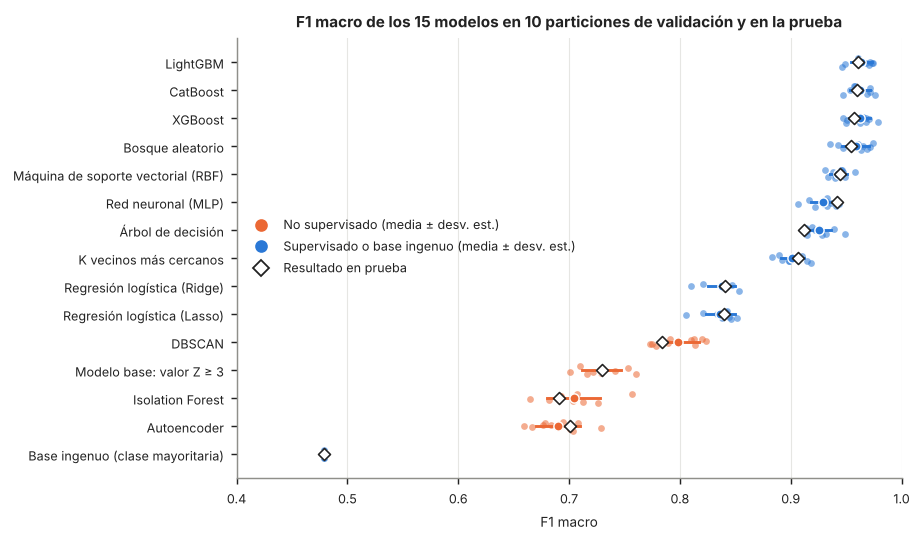

**F1 macro de los modelos en validación (10 particiones) y en la prueba.** Los modelos supervisados con mejor desempeño (LightGBM, CatBoost, XGBoost) superan 0,96 de F1 macro, mientras que los no supervisados quedan entre 0,69 y 0,80. El resultado en la prueba cae dentro de dos desviaciones estándar de la validación en 14 de 15 modelos; la diferencia prueba menos validación va de -0,015 a 0,012.

In [25]:
from sklearn.metrics import precision_recall_curve, roc_curve
# ---- Figura 1: comparación de modelos (F1 macro por partición y en la prueba) ----
orden_fig = resumen_cv["f1_macro_media"].sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(6.6, 4.4))
rng = np.random.default_rng(SEED)
for i, nom in enumerate(orden_fig):
    v = cv.loc[cv.modelo == nom, "f1_macro"].values
    col = NARANJA if M.MODELOS[nom]["tipo"] == "nosup" else AZUL
    ax.scatter(v, i + rng.uniform(-0.18, 0.18, len(v)), s=14, color=col, alpha=0.55, linewidths=0, zorder=2)
    ax.plot([v.mean() - v.std(), v.mean() + v.std()], [i, i], color=col, lw=1.6, zorder=3)
    ax.scatter(v.mean(), i, s=26, color=col, edgecolor="white", linewidth=0.8, zorder=4)
    ax.scatter(prueba.loc[nom, "f1_macro"], i, marker="D", s=22, color="white", edgecolor=TINTA, linewidth=0.9, zorder=5)
ax.set_yticks(range(len(orden_fig))); ax.set_yticklabels([M.MODELOS[k]["etiqueta"] for k in orden_fig])
ax.set_xlabel("F1 macro"); ax.set_xlim(0.4, 1.0)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", color=NARANJA, lw=0, label="No supervisado (media ± desv. est.)"),
                   Line2D([], [], marker="o", color=AZUL, lw=0, label="Supervisado o base ingenuo (media ± desv. est.)"),
                   Line2D([], [], marker="D", color="white", markeredgecolor=TINTA, lw=0, label="Resultado en prueba")], loc="upper left", bbox_to_anchor=(0.0, 0.62))
ax.set_title("F1 macro de los 15 modelos en 10 particiones de validación y en la prueba")
ax.grid(axis="y", visible=False)
guardar_fig(fig, "fig_obj2_comparacion_modelos")
dentro = [k for k in M.ORDEN if abs(prueba.loc[k, "f1_macro"] - resumen_cv.loc[k, "f1_macro_media"]) <= 2 * resumen_cv.loc[k, "f1_macro_sd"] + 1e-9]
dif = (prueba["f1_macro"] - resumen_cv["f1_macro_media"]).drop(index="base_ingenuo")
interpretar("fig_obj2_comparacion", "F1 macro de los modelos en validación (10 particiones) y en la prueba",
            [f"Los modelos supervisados con mejor desempeño ({', '.join(M.MODELOS[k]['etiqueta'] for k in sorted(M.ORDEN_SUP[1:], key=lambda k: -resumen_cv.loc[k, 'f1_macro_media'])[:3])}) superan {n(min(resumen_cv.loc[k,'f1_macro_media'] for k in sorted(M.ORDEN_SUP[1:], key=lambda k: -resumen_cv.loc[k, 'f1_macro_media'])[:3]), 2)} de F1 macro, mientras que los no supervisados quedan entre {n(min(resumen_cv.loc[k,'f1_macro_media'] for k in M.ORDEN_NOSUP), 2)} y {n(max(resumen_cv.loc[k,'f1_macro_media'] for k in M.ORDEN_NOSUP), 2)}.",
             f"El resultado en la prueba cae dentro de dos desviaciones estándar de la validación en {len(dentro)} de {len(M.ORDEN)} modelos; la diferencia prueba menos validación va de {n(dif.min(), 3)} a {n(dif.max(), 3)}."])

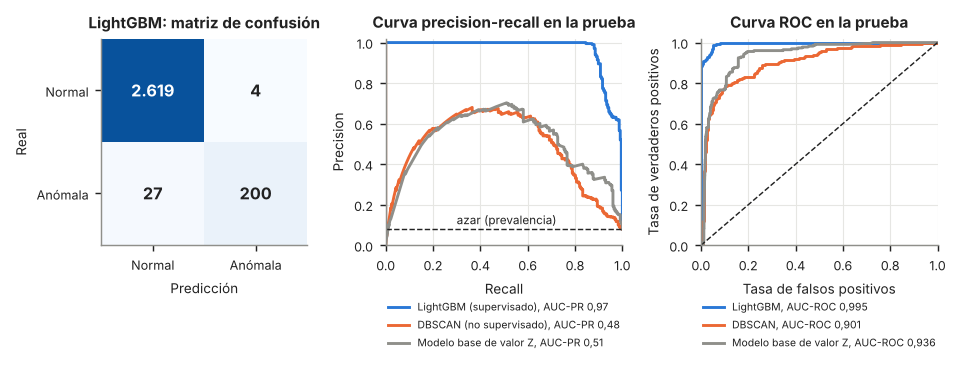

**Mejor modelo por F1 macro de validación: LightGBM.** En la prueba detecta 200 de 227 solicitudes anómalas con 4 falsas alarmas (precision 0,98, recall 0,88). Su AUC-ROC en la prueba es 0,995 y su AUC-PR 0,97, frente a 0,48 del mejor modelo no supervisado (DBSCAN) y 0,51 del modelo base; por ser supervisado usa la etiqueta, así que sirve como techo y no como solución aplicable sin etiquetas.

In [26]:
# ---- Figura 2: mejor modelo (matriz de confusión, curva precision-recall y curva ROC en la prueba) ----
mejor_global = resumen_cv.drop(index=["base_ingenuo"])["f1_macro_media"].idxmax()
fig, axs = plt.subplots(1, 3, figsize=(7.4, 3.0), gridspec_kw={"width_ratios": [1, 1.15, 1.15]})
ax = axs[0]
mat = np.array([[prueba.loc[mejor_global, "tn"], prueba.loc[mejor_global, "fp"]], [prueba.loc[mejor_global, "fn"], prueba.loc[mejor_global, "tp"]]], dtype=int)
ax.imshow(mat, cmap="Blues", vmin=0, vmax=mat.max() * 1.15)
for (i, j), v in np.ndenumerate(mat):
    ax.text(j, i, n(v), ha="center", va="center", color="white" if v > mat.max() / 2 else TINTA, fontsize=9, fontweight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal", "Anómala"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Normal", "Anómala"])
ax.set_xlabel("Predicción"); ax.set_ylabel("Real"); ax.grid(False)
ax.set_title(f"{M.MODELOS[mejor_global]['etiqueta']}: matriz de confusión")
ax = axs[1]
for nom, col, lab in [(mejor_global, AZUL, M.MODELOS[mejor_global]["etiqueta"] + " (supervisado)"), (mejor_nosup, NARANJA, M.MODELOS[mejor_nosup]["etiqueta"] + " (no supervisado)"), ("z_base", GRIS, "Modelo base de valor Z")]:
    p_, r_, _ = precision_recall_curve(y_te, salidas_prueba[nom][1])
    ax.plot(r_, p_, color=col, lw=1.6, label=f"{lab}, AUC-PR {n(prueba.loc[nom, 'auc_pr'], 2)}")
ax.axhline(y_te.mean(), color=TINTA, lw=0.8, ls="--"); ax.text(0.30, y_te.mean() + 0.025, "azar (prevalencia)", ha="left", fontsize=6.5)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=5.8); ax.set_title("Curva precision-recall en la prueba")
ax = axs[2]
for nom, col, lab in [(mejor_global, AZUL, M.MODELOS[mejor_global]["etiqueta"]), (mejor_nosup, NARANJA, M.MODELOS[mejor_nosup]["etiqueta"]), ("z_base", GRIS, "Modelo base de valor Z")]:
    fpr_, tpr_, _ = roc_curve(y_te, salidas_prueba[nom][1])
    ax.plot(fpr_, tpr_, color=col, lw=1.6, label=f"{lab}, AUC-ROC {n(prueba.loc[nom, 'auc_roc'], 3)}")
ax.plot([0, 1], [0, 1], color=TINTA, lw=0.8, ls="--")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=5.8); ax.set_title("Curva ROC en la prueba")
fig.tight_layout()
guardar_fig(fig, "fig_obj2_mejor_modelo")
RESULTADOS["mejor_modelo_global"] = mejor_global
interpretar("fig_obj2_mejor", f"Mejor modelo por F1 macro de validación: {M.MODELOS[mejor_global]['etiqueta']}",
            [f"En la prueba detecta {int(prueba.loc[mejor_global,'tp'])} de {int(y_te.sum())} solicitudes anómalas con {int(prueba.loc[mejor_global,'fp'])} falsas alarmas (precision {n(prueba.loc[mejor_global,'precision'], 2)}, recall {n(prueba.loc[mejor_global,'recall'], 2)}).",
             f"Su AUC-ROC en la prueba es {n(prueba.loc[mejor_global,'auc_roc'], 3)} y su AUC-PR {n(prueba.loc[mejor_global,'auc_pr'], 2)}, frente a {n(prueba.loc[mejor_nosup,'auc_pr'], 2)} del mejor modelo no supervisado ({M.MODELOS[mejor_nosup]['etiqueta']}) y {n(prueba.loc['z_base','auc_pr'], 2)} del modelo base; por ser supervisado usa la etiqueta, así que sirve como techo y no como solución aplicable sin etiquetas."])

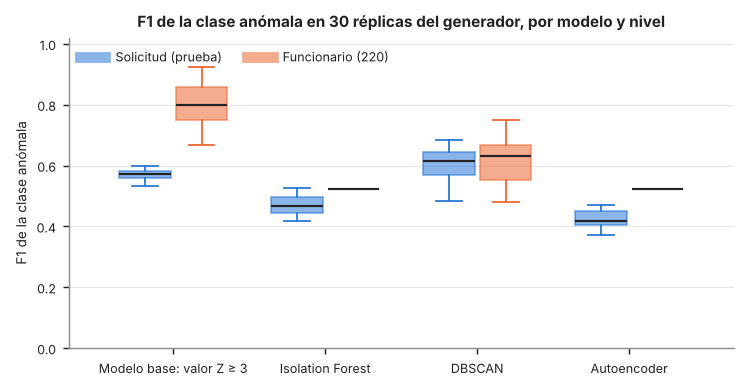

**F1 de la clase anómala en 30 réplicas del generador.** A nivel de solicitud, las medianas van de 0,42 a 0,61; a nivel de funcionario, de 0,52 a 0,80. El rango intercuartil medio entre réplicas es de 0,06 a nivel de funcionario y de 0,05 a nivel de solicitud: la dispersión es mayor con solo 6 casos positivos por réplica.

In [27]:
# ---- Figura 3: réplicas del generador (F1 de la clase anómala por modelo y nivel) ----
fig, ax = plt.subplots(figsize=(6.6, 3.1))
pos = np.arange(len(M.NUCLEO)); w = 0.34
for j, (niv, col, pref) in enumerate((("Solicitud (prueba)", AZUL, "sol_"), ("Funcionario (220)", NARANJA, "fun_"))):
    datos_box = [rep[f"{pref}{k}"].values for k in M.NUCLEO]
    bp = ax.boxplot(datos_box, positions=pos + (j - 0.5) * w * 1.1, widths=w, patch_artist=True, showfliers=False,
                    boxprops=dict(facecolor=col, alpha=0.55, edgecolor=col), medianprops=dict(color=TINTA, lw=1.2), whiskerprops=dict(color=col), capprops=dict(color=col))
    ax.plot([], [], color=col, lw=6, alpha=0.55, label=niv)
ax.set_xticks(pos); ax.set_xticklabels([M.MODELOS[k]["etiqueta"] for k in M.NUCLEO]); ax.set_ylabel("F1 de la clase anómala"); ax.set_ylim(0, 1.02)
ax.legend(loc="upper left", ncol=2); ax.set_title("F1 de la clase anómala en 30 réplicas del generador, por modelo y nivel"); ax.grid(axis="x", visible=False)
guardar_fig(fig, "fig_obj2_replicas")
iqr_f = np.mean([rep[f"fun_{k}"].quantile(.75) - rep[f"fun_{k}"].quantile(.25) for k in M.NUCLEO]); iqr_s = np.mean([rep[f"sol_{k}"].quantile(.75) - rep[f"sol_{k}"].quantile(.25) for k in M.NUCLEO])
interpretar("fig_obj2_rep", "F1 de la clase anómala en 30 réplicas del generador",
            [f"A nivel de solicitud, las medianas van de {n(min(rep[f'sol_{k}'].median() for k in M.NUCLEO), 2)} a {n(max(rep[f'sol_{k}'].median() for k in M.NUCLEO), 2)}; a nivel de funcionario, de {n(min(rep[f'fun_{k}'].median() for k in M.NUCLEO), 2)} a {n(max(rep[f'fun_{k}'].median() for k in M.NUCLEO), 2)}.",
             f"El rango intercuartil medio entre réplicas es de {n(iqr_f, 2)} a nivel de funcionario y de {n(iqr_s, 2)} a nivel de solicitud" + (": la dispersión es mayor con solo 6 casos positivos por réplica." if iqr_f > iqr_s else ".")])

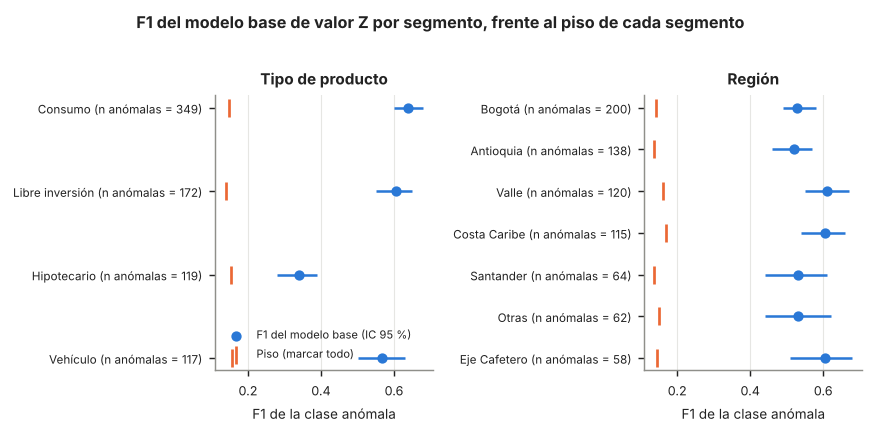

**F1 del modelo base por tipo de producto y región.** El modelo base supera el piso de su segmento en 11 de 11 segmentos, y el menor margen es de 0,186. El intervalo de 9 de 11 segmentos incluye el F1 global del modelo base (0,56); con pocas anómalas por segmento, las diferencias entre segmentos deben leerse con cautela.

In [28]:
# ---- Figura 4: F1 del modelo base por segmento y piso de referencia ----
fig, axs = plt.subplots(1, 2, figsize=(6.8, 3.2), sharex=True)
for ax, var in zip(axs, ("Tipo de producto", "Región")):
    sub_ = seg[seg.Variable == var].reset_index(drop=True)
    yy = np.arange(len(sub_))[::-1]
    ci = np.array([[float(t) for t in s_.split(" a ")] for s_ in sub_["IC Modelo base: valor Z ≥ 3"]])
    ax.hlines(yy, ci[:, 0], ci[:, 1], color=AZUL, lw=1.4)
    ax.scatter(sub_["F1 Modelo base: valor Z ≥ 3"], yy, color=AZUL, s=22, zorder=3, label="F1 del modelo base (IC 95 %)")
    ax.scatter(sub_["Piso de F1"], yy, marker="|", color=NARANJA, s=90, zorder=4, label="Piso (marcar todo)")
    ax.set_yticks(yy); ax.set_yticklabels([f"{a} (n anómalas = {b})" for a, b in zip(sub_["Segmento"], sub_["Anómalas"])], fontsize=6.5)
    ax.set_title(var); ax.set_xlabel("F1 de la clase anómala"); ax.grid(axis="y", visible=False)
axs[0].legend(loc="lower left", fontsize=6.2)
fig.suptitle("F1 del modelo base de valor Z por segmento, frente al piso de cada segmento", fontweight="bold", y=1.02, fontsize=9)
fig.tight_layout(); guardar_fig(fig, "fig_obj2_segmentos")
interpretar("fig_obj2_seg", "F1 del modelo base por tipo de producto y región",
            [f"El modelo base supera el piso de su segmento en {int((seg['F1 Modelo base: valor Z ≥ 3'] > seg['Piso de F1']).sum())} de {len(seg)} segmentos, y el menor margen es de {n((seg['F1 Modelo base: valor Z ≥ 3'] - seg['Piso de F1']).min(), 3)}.",
             f"El intervalo de {int(sum((lo <= g_tot['z_base'] <= hi) for lo, hi in [[float(t) for t in s_.split(' a ')] for s_ in seg['IC Modelo base: valor Z ≥ 3']]))} de {len(seg)} segmentos incluye el F1 global del modelo base ({n(g_tot['z_base'], 2)}); con pocas anómalas por segmento, las diferencias entre segmentos deben leerse con cautela."])

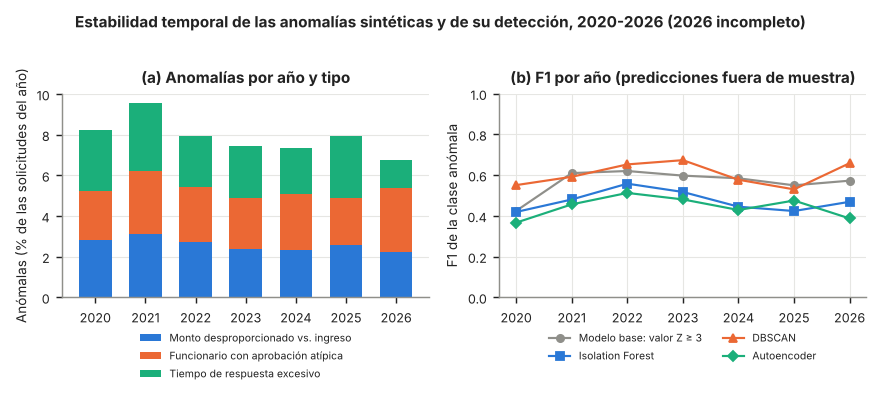

**Estabilidad temporal de las anomalías y de su detección.** La proporción de anómalas va de 6,8 % a 9,5 % en los 7 años; la prueba de homogeneidad da un valor p de 0,263. La correlación de Spearman entre año y prevalencia es -0,86 (valor p 0,01), calculada con solo 7 puntos y con 2026 incompleto: sugiere una tendencia que debe leerse con cautela, porque la prueba de homogeneidad por año no la confirma. El F1 del modelo base por año oscila entre 0,42 y 0,62; con pocas anómalas por año, esas diferencias no son concluyentes.

In [29]:
# ---- Figura 5: estabilidad temporal ----
fig, axs = plt.subplots(1, 2, figsize=(6.8, 3.0))
ax = axs[0]
base_ = np.zeros(len(est))
colores = [AZUL, NARANJA, AGUA]
for t, col in zip(M.TIPOS, colores):
    ax.bar(est["Año"].astype(str), 100 * est[t] / est["Solicitudes"], bottom=base_, color=col, label=t, width=0.65)
    base_ += 100 * (est[t] / est["Solicitudes"]).values
ax.set_ylabel("Anómalas (% de las solicitudes del año)"); ax.set_title("(a) Anomalías por año y tipo"); ax.legend(fontsize=5.8, loc="upper center", bbox_to_anchor=(0.5, -0.12)); ax.grid(axis="x", visible=False)
ax = axs[1]
for nom, col, mk in zip(M.NUCLEO, (GRIS, AZUL, NARANJA, AGUA), ("o", "s", "^", "D")):
    ax.plot(est["Año"], est[f"F1 {M.MODELOS[nom]['etiqueta']}"], marker=mk, ms=4, lw=1.2, color=col, label=M.MODELOS[nom]["etiqueta"])
ax.set_ylabel("F1 de la clase anómala"); ax.set_title("(b) F1 por año (predicciones fuera de muestra)"); ax.legend(fontsize=5.8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2); ax.set_ylim(0, 1)
fig.suptitle("Estabilidad temporal de las anomalías sintéticas y de su detección, 2020-2026 (2026 incompleto)", fontweight="bold", y=1.02, fontsize=8.5)
fig.tight_layout(); guardar_fig(fig, "fig_obj2_estabilidad_temporal")
interpretar("fig_obj2_est", "Estabilidad temporal de las anomalías y de su detección",
            [f"La proporción de anómalas va de {n(100 * est['Prevalencia'].min(), 1)} % a {n(100 * est['Prevalencia'].max(), 1)} % en los {len(est)} años; la prueba de homogeneidad da un valor p de {n(p_prev_a, 3)}.",
             f"La correlación de Spearman entre año y prevalencia es {n(rho, 2)} (valor p {n(p_rho, 2)}), calculada con solo {len(est)} puntos y con 2026 incompleto: {'no indica una tendencia' if p_rho > 0.05 else 'sugiere una tendencia que debe leerse con cautela, porque la prueba de homogeneidad por año no la confirma' if p_prev_a > 0.05 else 'indica una tendencia'}.",
             f"El F1 del modelo base por año oscila entre {n(est['F1 Modelo base: valor Z ≥ 3'].min(), 2)} y {n(est['F1 Modelo base: valor Z ≥ 3'].max(), 2)}; con pocas anómalas por año, esas diferencias no son concluyentes."])

## 16. Registro de experimentos

In [30]:
exps = pd.DataFrame(EXPS)
exps.to_csv(RES / "experiments.csv", index=False, encoding="utf-8-sig")
display(exps.groupby("etapa").size().rename("corridas").to_frame())
print(len(exps), "corridas registradas en results/experiments.csv")

,corridas
etapa,
ablacion_fe,12
ablacion_smote,4
funcionario,11
funcionario_oof,4
kdistancia,3
optuna,15
prueba,15
replica,240
sensibilidad,9


328 corridas registradas en results/experiments.csv


## 17. Comprobaciones finales

In [31]:
# Si alguna falla, el cuaderno se detiene
assert hashlib.sha256(idx_te.tobytes()).hexdigest() == HUELLA_PRUEBA, "La partición de prueba cambió."
assert set(cv.modelo) == set(M.ORDEN) and (cv.groupby("modelo").size() == 10).all()
assert all(len(mejores[k]) == len(M.MODELOS[k]["espacio"]) for k in M.ORDEN)
assert not set(idx_tr) & set(idx_te), "Entrenamiento y prueba comparten filas."
assert (pd.read_csv(RT / "metricas_por_particion.csv", encoding="utf-8-sig").shape[0] == 10 * len(M.ORDEN))
assert (exps.run_id.is_unique) and len(exps) > 0
assert len(rep) == 30 and set(M.NUCLEO) <= set(oof), "Faltan réplicas o predicciones fuera de muestra."
assert (RT / "metricas_por_tipo_prueba.csv").exists() and (RT / "segmentos_producto_region.csv").exists() and (RT / "estabilidad_temporal.csv").exists()
RESULTADOS["tablas_generadas"] = sorted(p.name for p in RT.glob("*.csv"))
RESULTADOS["figuras_generadas"] = sorted(p.name for p in FIG.glob("fig_obj2_*.png"))
RESULTADOS["n_corridas_registradas"] = int(len(exps))
RESULTADOS["mejores_hiperparametros"] = {k: v for k, v in mejores.items()}
(RES / "resultados_obj2.json").write_text(json.dumps(RESULTADOS, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")
print("Todas las comprobaciones pasaron.")
print(len(RESULTADOS["tablas_generadas"]), "tablas en results/tables y", len(RESULTADOS["figuras_generadas"]), "figuras nuevas.")

Todas las comprobaciones pasaron.
31 tablas en results/tables y 5 figuras nuevas.


## 18. Bitácora de decisiones del objetivo 2

Las decisiones marcadas como **supuesto** se tomaron para poder avanzar y están pendientes de confirmación del tutor o del profesor.

In [32]:
bit2 = pd.DataFrame([
    ("2026-11-10", "Mantener los cuatro modelos no supervisados como núcleo y agregar modelos supervisados como referencia («techo»).", "Cambiar a una batería solo supervisada; omitir los supervisados.", "La lista técnica del profesor pide una batería supervisada, pero el objetivo 2 compara el modelo base, Isolation Forest, DBSCAN y el autoencoder. Mantener ambos cumple la lista sin cambiar el objetivo.", "Secciones 3 a 6", "Supuesto: confirmar con el tutor o el profesor"),
    ("2026-11-10", "Usar la etiqueta para ajustar hiperparámetros solo sobre los pliegues de validación del entrenamiento.", "No usar la etiqueta (valores por defecto o reglas fijas); usarla también en la prueba.", "Optuna necesita una métrica para comparar configuraciones. Esto modifica la regla del protocolo («las etiquetas nunca ajustan umbrales»), por lo que se limita a validación y nunca a la prueba.", "Sección 3", "Confirmada por el profesor con la salvedad declarada; actualizar el protocolo del informe"),
    ("2026-11-10", "Optuna con 20 pruebas, muestreador TPE con semilla 42 y 3 pliegues internos, igual para todos los modelos.", "Más pruebas; búsqueda en malla; pruebas distintas por modelo.", "Garantiza una comparación justa con un costo de cómputo manejable (2 núcleos).", "results/tables/optuna_*.csv", "Adoptada"),
    ("2026-11-10", "Validación repetida 5×2 sobre el entrenamiento y evaluación única en la prueba 70/30 del protocolo.", "10×3; TimeSeriesSplit.", "Es la configuración mínima de la lista del profesor y respeta la partición 70/30 ya definida. La partición es aleatoria, no temporal, porque las solicitudes no se modelan como serie.", "results/tables/metricas_por_particion.csv", "Adoptada"),
    ("2026-11-10", "Calcular rezagos y ventanas móviles por funcionario antes de la partición, usando solo solicitudes anteriores y nunca la etiqueta.", "Calcularlas dentro del Pipeline; no usar ventanas.", "No aprenden parámetros y son causales; calcularlas antes evita reimplementarlas por partición. Las ventanas de una solicitud de entrenamiento pueden usar valores (sin etiqueta) de solicitudes anteriores que quedaron en la prueba.", "src/modelado.py (agregar_temporales)", "Adoptada; revisar si el tutor prefiere partición temporal"),
    ("2026-11-10", "Desbalance: pesos de clase (o scale_pos_weight como hiperparámetro) en la batería y SMOTE como variante en la ablación, solo dentro del Pipeline y con el entrenamiento.", "Solo SMOTE; submuestreo; ningún tratamiento.", "Los pesos no alteran los datos; SMOTE se compara aparte para medir su efecto.", "Sección 8.2", "Adoptada"),
    ("2026-11-10", "No usar LSTM ni GRU.", "Modelar cada funcionario como secuencia de solicitudes.", "Las solicitudes se modelan como filas y la dimensión temporal entra con rezagos y ventanas móviles; el tamaño de los datos (9.500 filas) tampoco justifica redes recurrentes.", "Sección 2", "Adoptada"),
    ("2026-11-10", "Implementar el autoencoder con MLPRegressor de scikit-learn.", "Usar PyTorch o TensorFlow.", "Mantiene las dependencias livianas y reproducibles en Colab; el error de reconstrucción es el puntaje de anomalía.", "src/modelado.py (DetectorAE)", "Adoptada"),
    ("2026-11-10", "Excluir de los modelos los identificadores, el conteo creditos_aprobados_funcionario, la fecha cruda, las banderas del ETL y las columnas redundantes.", "Incluirlas.", "El identificador permitiría memorizar filas, el conteo es una fuga indirecta y las banderas o columnas redundantes no aportan información.", "results/tables/columnas_excluidas.csv", "Adoptada"),
    ("2026-11-15", "Contraste de H1 y H2 con Wilcoxon sobre 30 réplicas del generador (semillas 101 a 130), como define el protocolo; la prueba sobre las 10 particiones queda como evidencia complementaria.", "Solo particiones; más réplicas.", "El protocolo del ACA 1 define las 30 réplicas y el profesor espera el contraste de hipótesis en 8.6.2. Las réplicas usan los hiperparámetros del dataset principal, sin reoptimizar, y el generador se ejecuta sin modificar el archivo del repositorio.", "Secciones 7 y 14", "Adoptada"),
    ("2026-11-15", "Adoptar la estructura 8.5 (Modelado) y 8.6 (Evaluación) propuesta por el profesor; la batería supervisada y la ablación pasan a material complementario.", "Una fase por objetivo; batería supervisada en el cuerpo.", "El profesor describe el proyecto como análisis no supervisado y su estructura incluye solo el modelo base, Isolation Forest, DBSCAN y el autoencoder.", "Retroalimentación del ACA 1", "Adoptada; confirmar la batería supervisada como complemento"),
    ("2026-11-15", "Mantener las variables nuevas (calendario, rezagos y ventanas móviles) y medir su aporte con una ablación en tres niveles: sin derivadas, solo apartado 8.4.3 y completo.", "Usar solo las variables del apartado 8.4.3.", "El profesor pide usar las variables de 8.4.3, pero la lista técnica del ACA 2 exige rezagos, ventanas móviles y calendario; la ablación muestra el aporte de cada nivel y las nuevas se declaran como ampliación.", "Sección 8.1", "Supuesto: confirmar con el profesor"),
    ("2026-11-15", "Analizar subgrupos y años con predicciones fuera de muestra sobre las 9.500 solicitudes (5 pliegues) de los modelos no supervisados, con hiperparámetros ya fijados.", "Usar solo la prueba (227 anómalas).", "La prueba deja muy pocas anómalas por segmento; el ajuste de los modelos no ve la etiqueta, aunque los hiperparámetros sí se eligieron con la del entrenamiento, por lo que el análisis es exploratorio.", "Secciones 12 y 13", "Adoptada"),
    ("2026-11-15", "El F1 de la clase anómala es la métrica principal (protocolo); el F1 macro se usa además como objetivo de Optuna y se reporta junto al primero.", "Optimizar el F1 de la clase anómala.", "La lista técnica del ACA 2 pide F1 macro; el protocolo del informe define el F1 de la clase anómala. Se reportan ambos.", "Secciones 3 a 7", "Adoptada"),
    ("2026-11-10", "Nivel de funcionario sin partición y sin ajuste de hiperparámetros con la etiqueta; resultados con intervalos de remuestreo.", "Validación agrupada por funcionario.", "Solo hay 6 funcionarios atípicos; cualquier partición deja uno o dos por pliegue.", "Sección 10", "Confirmada por el profesor: intervalos de remuestreo y evaluación fuera de muestra (sección 10.1)"),
    ("2026-11-16", "Evaluar el nivel de funcionario también con predicciones fuera de muestra (3 pliegues estratificados × 20 repeticiones), con la referencia de pares y el detector calculados sin el funcionario evaluado.", "Mantener solo la evaluación sobre los 220 funcionarios.", "El profesor advirtió del riesgo de fuga entre niveles; con 6 atípicos no se puede particionar 70/30, pero sí medir cuánto cambia el F1 cuando el modelo no ha visto al funcionario.", "Sección 10.1", "Adoptada por recomendación del profesor"),
    ("2026-11-16", "Contrastar el eps de DBSCAN hallado con Optuna con el codo del gráfico de k-distancias (sin etiquetas), con k = min_samples de Optuna y k = 2·d. La prueba solo describe; no se elige con ella.", "Usar solo el eps de Optuna.", "El profesor sugirió el contraste por la alta sensibilidad de DBSCAN a eps; permite mostrar cuánto del desempeño depende de haber usado la etiqueta.", "Sección 5.1", "Adoptada por sugerencia del profesor"),
], columns=["Fecha", "Decisión", "Alternativas consideradas", "Por qué", "Evidencia", "Estado"])
guardar_doc(bit2, "tabla_bitacora_decisiones_obj2")
display(bit2.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Fecha,Decisión,Alternativas consideradas,Por qué,Evidencia,Estado
2026-11-10,Mantener los cuatro modelos no supervisados como núcleo y agregar modelos supervisados como referencia («techo»).,Cambiar a una batería solo supervisada; omitir los supervisados.,"La lista técnica del profesor pide una batería supervisada, pero el objetivo 2 compara el modelo base, Isolation Forest, DBSCAN y el autoencoder. Mantener ambos cumple la lista sin cambiar el objetivo.",Secciones 3 a 6,Supuesto: confirmar con el tutor o el profesor
2026-11-10,Usar la etiqueta para ajustar hiperparámetros solo sobre los pliegues de validación del entrenamiento.,No usar la etiqueta (valores por defecto o reglas fijas); usarla también en la prueba.,"Optuna necesita una métrica para comparar configuraciones. Esto modifica la regla del protocolo («las etiquetas nunca ajustan umbrales»), por lo que se limita a validación y nunca a la prueba.",Sección 3,Confirmada por el profesor con la salvedad declarada; actualizar el protocolo del informe
2026-11-10,"Optuna con 20 pruebas, muestreador TPE con semilla 42 y 3 pliegues internos, igual para todos los modelos.",Más pruebas; búsqueda en malla; pruebas distintas por modelo.,Garantiza una comparación justa con un costo de cómputo manejable (2 núcleos).,results/tables/optuna_*.csv,Adoptada
2026-11-10,Validación repetida 5×2 sobre el entrenamiento y evaluación única en la prueba 70/30 del protocolo.,10×3; TimeSeriesSplit.,"Es la configuración mínima de la lista del profesor y respeta la partición 70/30 ya definida. La partición es aleatoria, no temporal, porque las solicitudes no se modelan como serie.",results/tables/metricas_por_particion.csv,Adoptada
2026-11-10,"Calcular rezagos y ventanas móviles por funcionario antes de la partición, usando solo solicitudes anteriores y nunca la etiqueta.",Calcularlas dentro del Pipeline; no usar ventanas.,No aprenden parámetros y son causales; calcularlas antes evita reimplementarlas por partición. Las ventanas de una solicitud de entrenamiento pueden usar valores (sin etiqueta) de solicitudes anteriores que quedaron en la prueba.,src/modelado.py (agregar_temporales),Adoptada; revisar si el tutor prefiere partición temporal
2026-11-10,"Desbalance: pesos de clase (o scale_pos_weight como hiperparámetro) en la batería y SMOTE como variante en la ablación, solo dentro del Pipeline y con el entrenamiento.",Solo SMOTE; submuestreo; ningún tratamiento.,Los pesos no alteran los datos; SMOTE se compara aparte para medir su efecto.,Sección 8.2,Adoptada
2026-11-10,No usar LSTM ni GRU.,Modelar cada funcionario como secuencia de solicitudes.,Las solicitudes se modelan como filas y la dimensión temporal entra con rezagos y ventanas móviles; el tamaño de los datos (9.500 filas) tampoco justifica redes recurrentes.,Sección 2,Adoptada
2026-11-10,Implementar el autoencoder con MLPRegressor de scikit-learn.,Usar PyTorch o TensorFlow.,Mantiene las dependencias livianas y reproducibles en Colab; el error de reconstrucción es el puntaje de anomalía.,src/modelado.py (DetectorAE),Adoptada
2026-11-10,"Excluir de los modelos los identificadores, el conteo creditos_aprobados_funcionario, la fecha cruda, las banderas del ETL y las columnas redundantes.",Incluirlas.,"El identificador permitiría memorizar filas, el conteo es una fuga indirecta y las banderas o columnas redundantes no aportan información.",results/tables/columnas_excluidas.csv,Adoptada
2026-11-15,"Contraste de H1 y H2 con Wilcoxon sobre 30 réplicas del generador (semillas 101 a 130), como define el protocolo; la prueba sobre las 10 particiones queda como evidencia complementaria.",Solo particiones; más réplicas.,"El protocolo del ACA 1 define las 30 réplicas y el profesor espera el contraste de hipótesis en 8.6.2. Las réplicas usan los hiperparámetros del dataset principal, sin reoptimizar, y el generador se ejecuta sin modificar el archivo del repositorio.",Secciones 7 y 14,Adoptada
